# Where an algorithm ban sends an AI coder

**Demo notebook for the experiment "What does a ban switch the model to?"**

When a prompt says *"Do not use BFS"*, the model has to put its probability mass somewhere else. This experiment
ran a behavioural screen on **Qwen/Qwen3-8B** (thinking off, vLLM 0.11, T = 1.0, top-p 1.0, no top-k) to compare
two rival predictors of *where* that mass goes:

| Predictor | Idea | How it is built |
|---|---|---|
| **Substitution by association** (proposed) | a ban sends the model to whatever it associates with "the standard alternative to X" | 20 permuted-order rankings of the other modes, elicited from the model itself for each mode X and Borda-aggregated |
| **Typicality ladder** (baseline) | a ban deletes X; the remaining baseline frequencies decide | the baseline frequency of every surviving mode, renormalised over the survivors |

The screen uses two path-search tasks. **T1** is an unweighted grid path with 6 catalogue modes: BFS, DFS,
bidirectional BFS, IDDFS, A*/greedy best-first and Dijkstra. **T2** is a weighted shortest path with 5 modes:
Dijkstra, Bellman-Ford/SPFA, bidirectional Dijkstra, Floyd-Warshall and Dial. Every prediction was sha256
hash-chained into `commitments.log` **before** the samples it predicts were generated.

**What this notebook runs.** `method.py` is the orchestrator, with one sub-command per stage. The generation stages
need a `vllm serve` process with Qwen3-8B on a GPU, and the judge needs an OpenRouter key. Neither fits a 10-minute
CPU demo. The notebook therefore follows the artifact's own *Path A* (exact re-analysis from the published raw
generations): it **replays the recorded Qwen3-8B generations** for a curated subset of 100 programs
(`mini_demo_data.json`) and runs every CPU stage on them with the original code.

| `method.py` stage | In this notebook |
|---|---|
| `prompts`: build and freeze `prompts/conditions.json` | **runs**; the rebuilt prompt file is checked against the committed sha256 |
| `smoke`, `preban`, `bans`, `succession`: GPU generation | the request plans and per-request seeds **run**; the generations are **replayed** from the recorded rows |
| `label`: code extraction, runtime tracer + AST rules, blind judge, combine | **runs** on cached tracer probes and test results; judge labels come from the judge cache, with no API call |
| `elicit`, `assoc`: ranking parsing, Borda association map, baseline frequencies | **runs** |
| `freeze`: predictions hash-committed before any ban prompt | the frozen prediction files are checked against the hash chain; the association, frequency and free-text predictions are recomputed and compared |
| `score`: event outcomes, log-score contest, disguised recurrence, mention effects | **runs** |
| `tasks`, `gate`, `external`, `reference_map`, `outputs` | not part of the demo (sandbox harness, gold-set adjudication, other model families); their results are quoted from the full run |

**Full-run results to look for.**
- The baselines are fully collapsed: T1 is 100 % BFS and T2 is 100 % Dijkstra.
- A ban of the modal mode lands entirely on **DFS** (T1) and **Bellman-Ford/SPFA** (T2).
- The Borda association map **misses T1**: it nominates Dijkstra and ranks DFS last. It **hits T2**.
- Double bans fail: the model re-implements the banned mechanism under another name.

In [1]:
# Install dependencies (Colab-safe pattern: never reinstall Colab's pre-installed scientific stack on Colab)
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (the experiment used loguru 0.7.3)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py: original import block ----
import argparse  # method.py reads the stage name from the command line; the notebook calls the stages directly
import json
import sys
from typing import Any

from loguru import logger

# from common import (DATA_DIR, DECODING_FREE, DECODING_MAIN, DECODING_RANK, DECODING_T13, MODES, PROMPT_DIR, TASKS,
#                     commit_file, read_jsonl, request_seed, setup_logging, write_json)
# -> common.py is reproduced in a cell below (without its file-system paths)

# ---- imports used by the modules the stages call (common.py, gen/prompts.py, labeller/*, analysis/*) ----
import ast
import hashlib
import math
import random
import re
from collections import Counter
from datetime import datetime, timezone
from types import SimpleNamespace

import numpy as np

# ---- notebook additions: tables and figures ----
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-1/experiment-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]          # elicitation rows, caches, commitment log, frozen predictions, full-run numbers
EXAMPLES = data["examples"]      # recorded Qwen3-8B program generations (raw generation schema + full-run labels)
print(f"{len(EXAMPLES)} recorded programs:", META["examples_per_condition"])
print(f"{len(META['elicitation']['rank_rows'])} ranking rows, {len(META['elicitation']['free_rows'])} free-text rows, "
      f"{len(META['eval_cache'])} cached program evaluations, {len(META['judge_cache'])} cached judge labels, "
      f"{len(META['commitments'])} commitment-log entries, {len(META['frozen_predictions'])} frozen prediction files")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
100 recorded programs: {'t1|baseline': 10, 't2|baseline': 10, 't1|ban:bfs': 25, 't2|ban:dijkstra': 25, 't1|mention:dfs': 5, 't2|mention:bf_spfa': 5, 't1|succession:2': 10, 't2|succession:2': 10}
40 ranking rows, 40 free-text rows, 96 cached program evaluations, 29 cached judge labels, 5 commitment-log entries, 4 frozen prediction files


## Configuration

All tunable parameters are set here. The generation settings themselves (T = 1.0, top-p 1.0, max_tokens 1024, n
samples per request) live in the original `program_req` and request builders below. They only matter for new
generations, and the notebook replays recorded ones.

`mini_demo_data.json` holds at most 25 recorded programs per condition: 10 per baseline, 25 per modal ban arm,
5 per mention twin and 10 per succession step. The original values are given in the comments.

In [5]:
# Recorded programs replayed per (task, condition); 25 = everything in mini_demo_data.json.
# Original run: N = 300 per baseline, 100 per ban arm, 100 per succession step, 50 per mention twin -- that needs
# the full raw generations (3,260 programs, the experiment's Path A), not this 100-program demo subset:
# MAX_ROWS_PER_CONDITION = 300
MAX_ROWS_PER_CONDITION = 25

# Ranking samples per banned mode X fed into the Borda association map (original: N_RANK_SAMPLES = 20).
N_RANKINGS_PER_X = 20

# Free-text "standard alternative to X" answers per X (original: N_FREE_SAMPLES = 20).
N_FREETEXT_PER_X = 20

# Bootstrap resamples for the paired log-score CI (original: 2000) and the frequency-nomination stability (original: 1000).
N_BOOT = 2000
N_BOOT_STABILITY = 1000

## 1. Frozen protocol constants (`common.py`)

Everything that defines the protocol lives in one module, so every stage reads one frozen definition:

- the task texts (SPEC = DESCRIPTION + blank line + FORMAT);
- the catalogue of algorithm modes and their display names;
- the one-line mode definitions shown to the blind judge;
- the pre-registered thresholds and the decoding tags.

`request_seed` gives every generation request a deterministic seed. `sha256_text` and `verify_chain` implement the
hash chain.

**Notebook changes:**
- The directory constants, the `mkdir` loop, the JSONL/JSON file writers and the log-file sink are dropped.
- `read_commitments()` reads the commitment log shipped in `mini_demo_data.json` instead of `commitments.log`.

In [6]:
MODEL_ID = "Qwen/Qwen3-8B"  # original: os.environ.get("SCREEN_MODEL", "Qwen/Qwen3-8B")
SERVED_NAME = "qwen3-screen"
EXT_MODEL = "meta-llama/llama-3.1-8b-instruct"
JUDGE_MODEL = "openai/gpt-4.1-mini"
GOLD_JUDGES = ("openai/gpt-4.1-mini", "google/gemini-2.5-flash")
GOLD_TIEBREAK = "deepseek/deepseek-chat-v3.1"

TASKS = ("t1", "t2")
TASK_DATASET_NAME = {"t1": "T1_grid_path", "t2": "T2_weighted_shortest_path"}
TASK_SUBDIR = {"t1": "t1_grid", "t2": "t2_wsp"}

T1_DESCRIPTION = (
    "Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. "
    "grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; "
    "the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of "
    "0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not "
    "leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, "
    "and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does "
    "not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, "
    "or start or goal is a wall, return []."
)
T2_DESCRIPTION = (
    "Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node "
    "s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list "
    "of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most "
    "600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight "
    "of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s."
)
FORMAT_TEXT = (
    "Use only the Python standard library. Return only one ```python code block containing the function solve "
    "and any helpers, with no example usage and no explanation."
)
DESCRIPTION = {"t1": T1_DESCRIPTION, "t2": T2_DESCRIPTION}


def spec_text(task: str) -> str:
    """SPEC = DESCRIPTION + blank line + FORMAT."""
    return DESCRIPTION[task] + "\n\n" + FORMAT_TEXT


CATALOGUE: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* or greedy best-first search",
        "dijkstra": "Dijkstra's algorithm",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
MODES = {t: list(CATALOGUE[t].keys()) for t in TASKS}
OTHER = "other"
UNKNOWN = "unknown"
NO_CODE = "no_code"

# One-line definitions shown to the blind judge (never the condition).
MODE_DEFINITIONS: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search: explores cells in order of distance from start using a FIFO queue "
               "(deque.popleft, list.pop(0), queue.Queue) or level-by-level frontier lists; one search direction.",
        "dfs": "depth-first search: explores along one branch as deep as possible using recursion or a LIFO stack "
               "(list.pop(), deque.pop(), LifoQueue), with a visited set; no depth-limit iterations.",
        "bibfs": "bidirectional BFS: two breadth-first searches, one from start and one from goal, expanded "
                 "alternately until the frontiers meet; the path is joined at the meeting cell.",
        "iddfs": "iterative deepening DFS: repeated depth-limited depth-first searches with an increasing depth "
                 "limit (0, 1, 2, ...) until the goal is found.",
        "astar_gbfs": "A* search or greedy best-first search: a priority queue ordered by a heuristic estimate of "
                      "the distance to the goal (e.g. Manhattan distance), either f = g + h (A*) or h alone (greedy).",
        "dijkstra": "Dijkstra's algorithm: a priority queue (heap) ordered by distance from start only, with no "
                    "heuristic toward the goal (on a unit-weight grid).",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm: a single priority queue (heap) of tentative distances from s, popping the "
                    "smallest distance each time (lazy deletion or decrease-key variants), one search direction.",
        "bf_spfa": "Bellman-Ford (repeated relaxation passes over all edges, up to n-1 rounds, possibly with early "
                   "exit) or SPFA (a FIFO queue of nodes whose distance improved, often with an in-queue flag).",
        "bidijkstra": "bidirectional Dijkstra: two Dijkstra searches, forward from s on the graph and backward from t "
                      "on the reversed graph, with a meeting/stopping rule.",
        "floyd": "Floyd-Warshall: all-pairs shortest paths with a triple loop over k, i, j updating "
                 "dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j]).",
        "dial": "Dial's algorithm: Dijkstra with a bucket queue, i.e. an array or dict of buckets indexed by distance, "
                "scanned in increasing distance order instead of a binary heap.",
    },
}
EXTENDED_CATALOGUE = {
    "t1": ["bidirectional A*/Dijkstra", "jump point search", "beam search", "random walk"],
    "t2": ["DAG dynamic programming", "Johnson's algorithm", "A* with a non-zero heuristic"],
}

# Pre-registration thresholds (never tuned on outcomes).
THRESHOLDS = {
    "presence": 0.10,
    "compliance_informative": 0.50,
    "realised_margin": 0.15,
    "stability": 0.80,
    "uniform_mix": 0.05,
    "other_floor": 0.02,
    "min_compliant": 20,
    "t9_min_compliant": 10,
}
DECODING_MAIN = "T1.0_topp1.0_topk-off_max1024_thinkoff"
DECODING_T13 = "T1.3_topp1.0_topk-off_max1024_thinkoff"
DECODING_RANK = "T1.0_topp1.0_topk-off_max64_thinkoff"
DECODING_FREE = "T1.0_topp1.0_topk-off_max32_thinkoff"


def setup_logging(name: str) -> None:
    """loguru: stdout INFO (+ a rotating DEBUG file sink per stage in the original; dropped in the notebook)."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def request_seed(task: str, condition: str, paraphrase_id: int | str, stage: str) -> int:
    """Per-request seed = int(sha256('task|condition|paraphrase|stage')[:8], 16)."""
    return int(hashlib.sha256(f"{task}|{condition}|{paraphrase_id}|{stage}".encode()).hexdigest()[:8], 16)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np  # local import: keeps the sandbox runner free of numpy

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def join_names_or(names: list[str]) -> str:
    """'A', 'A or B', 'A, B or C' (ban order preserved)."""
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def join_names_and(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " and " + names[-1]


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def read_commitments() -> list[dict[str, Any]]:
    return list(META["commitments"])  # original: read_jsonl(COMMIT_LOG)


def verify_chain() -> tuple[bool, list[str]]:
    """Recompute the hash chain; returns (ok, problems)."""
    problems: list[str] = []
    prev = "0" * 64
    for i, e in enumerate(read_commitments()):
        if e["prev_entry_hash"] != prev:
            problems.append(f"entry {i}: prev hash mismatch")
        if sha256_text(e["prev_entry_hash"] + e["sha"] + e["utc_time"]) != e["entry_hash"]:
            problems.append(f"entry {i}: entry hash mismatch")
        prev = e["entry_hash"]
    return (not problems, problems)


setup_logging("method_demo")  # method.py main() calls setup_logging(f"method_{args.stage}")

## 2. Prompt construction (`gen/prompts.py`)

Every generation prompt is `[condition segment] + blank line + [SPEC]`. The conditions are:

- 10 neutral `baseline` segments, and `baseline_empty` (SPEC only);
- for every catalogue mode X: 10 `ban` paraphrases, 10 `mention` twins (which name X without banning it) and
  5 `forced` paraphrases;
- `listall`, which names every catalogue mode in a seeded random order.

The elicitation prompts ask the model either to rank the other modes "by how standard an alternative to X each one
is" (20 permuted option orders per X), or to name "the standard alternative to X" in free text. A succession prompt
bans the cumulative set of banned modes ("A, B or C"). This module is copied unchanged, except for
`conditions_path()`, which only returned the output file path.

In [7]:
BASELINE_SEGMENTS = [
    "Please solve the following programming task.",
    "Here is a programming task for you.",
    "Solve the task described below.",
    "Below is a coding problem to solve.",
    "Please write code for the following task.",
    "The following task needs a Python solution.",
    "Complete the programming task below.",
    "Your job is to solve this coding task.",
    "Implement a solution to the following problem.",
    "Read the task below and solve it.",
]
BAN_TEMPLATES = [
    "Do not use {X}.",
    "Your solution must not use {X}.",
    "Avoid using {X} in your solution.",
    "{X} is not allowed for this task.",
    "Do not implement {X}.",
    "You may use any approach except {X}.",
    "Please refrain from using {X}.",
    "The solution must not rely on {X}.",
    "Using {X} is forbidden here.",
    "Don't use {X}.",
]
MENTION_TEMPLATES = [
    "{X} is one well-known approach to this task; implement any correct algorithm.",
    "{X} is a known way to solve this task; any correct algorithm is fine.",
    "{X} is one common approach here; implement any correct algorithm.",
    "{X} is one of the standard approaches to this task; use any correct algorithm.",
    "One well-known approach to this task is {X}; implement any correct algorithm.",
    "{X} is a familiar technique for this task; any correct solution is acceptable.",
    "{X} is one established method for this task; implement any correct algorithm.",
    "People often solve this task with {X}; implement any correct algorithm.",
    "{X} is one possible approach; implement any correct algorithm.",
    "{X} is one textbook approach to this task; any correct algorithm will do.",
]
LISTALL_TEMPLATES = [
    "Known approaches include {L}; implement any correct algorithm.",
    "Approaches to this task include {L}; any correct algorithm is fine.",
    "This task can be solved with {L}; implement any correct algorithm.",
    "Standard approaches here are {L}; use any correct algorithm.",
    "Well-known methods for this task include {L}; implement any correct algorithm.",
    "Possible approaches include {L}; any correct solution is acceptable.",
    "Common techniques for this task are {L}; implement any correct algorithm.",
    "Among the known approaches are {L}; implement any correct algorithm.",
    "You could use {L}; any correct algorithm will do.",
    "Textbook approaches include {L}; implement any correct algorithm.",
]
FORCED_TEMPLATES = [
    "Implement {X} for this task.",
    "Use {X} to solve this task.",
    "Solve this task with {X}.",
    "Your solution should use {X}.",
    "Write an implementation based on {X}.",
]
RANK_TEMPLATE = (
    "Consider the approach {X}. Rank the following approaches by how standard an alternative to {X} each one is "
    "for this task, from the most standard alternative to the least standard."
)
RANK_ANSWER = "Answer with only a JSON list of the option letters, most standard first, using every letter exactly once."
FREE_TEMPLATE = "What is the standard alternative to {X} for this task? Answer with the name of one algorithm only."
N_RANK_SAMPLES = 20
N_FREE_SAMPLES = 20


def make_prompt(task: str, segment: str | None) -> str:
    """Shared prompt = [condition segment] + blank line + [SPEC]; no segment for baseline_empty."""
    if segment is None:
        return spec_text(task)
    return cap_first(segment) + "\n\n" + spec_text(task)


def fill(template: str, **kw: str) -> str:
    out = template
    for k, v in kw.items():
        out = out.replace("{" + k + "}", v)
    return cap_first(out)


def listall_order(task: str, pid: int) -> list[str]:
    modes = list(MODES[task])
    random.Random(f"listall|{task}|{pid}").shuffle(modes)
    return modes


def rank_option_order(task: str, x: str, i: int) -> list[str]:
    others = [m for m in MODES[task] if m != x]
    random.Random(f"rank|{task}|{x}|{i}").shuffle(others)
    return others


def rank_prompt(task: str, x: str, order: list[str]) -> str:
    names = CATALOGUE[task]
    lines = [f"{chr(ord('A') + j)}. {names[m]}" for j, m in enumerate(order)]
    return (DESCRIPTION[task] + "\n\n" + RANK_TEMPLATE.replace("{X}", names[x]) + "\n" + "\n".join(lines) + "\n"
            + RANK_ANSWER)


def free_prompt(task: str, x: str) -> str:
    return DESCRIPTION[task] + "\n\n" + FREE_TEMPLATE.replace("{X}", CATALOGUE[task][x])


def succession_segments(task: str, banned_in_order: list[str]) -> list[str]:
    names = join_names_or([CATALOGUE[task][m] for m in banned_in_order])
    return [fill(t, X=names) for t in BAN_TEMPLATES]


def build_conditions() -> dict[str, Any]:
    out: dict[str, Any] = {
        "templates": {
            "baseline": BASELINE_SEGMENTS, "ban": BAN_TEMPLATES, "mention": MENTION_TEMPLATES,
            "listall": LISTALL_TEMPLATES, "forced": FORCED_TEMPLATES, "rank": RANK_TEMPLATE,
            "rank_answer": RANK_ANSWER, "free": FREE_TEMPLATE,
            "succession": "ban templates with {X} = cumulative banned display names joined 'A, B or C' in ban order",
        },
        "rules": {
            "prompt": "[condition segment] + blank line + [SPEC]; SPEC = DESCRIPTION + blank line + FORMAT",
            "capitalisation": "first character of every condition segment is upper-cased (templates that start "
                              "with {X} would otherwise begin a sentence in lower case)",
            "listall_join": "all catalogue display names, seeded random order per paraphrase, joined 'A, B and C'",
        },
        "name_table": CATALOGUE,
        "spec": {t: spec_text(t) for t in TASKS},
        "tasks": {},
    }
    for task in TASKS:
        names = CATALOGUE[task]
        conds: dict[str, list[dict[str, Any]]] = {}
        conds["baseline"] = [{"paraphrase_id": i, "segment": s, "prompt": make_prompt(task, s)}
                             for i, s in enumerate(BASELINE_SEGMENTS)]
        conds["baseline_empty"] = [{"paraphrase_id": 0, "segment": None, "prompt": make_prompt(task, None)}]
        for m in MODES[task]:
            conds[f"ban:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                  "prompt": make_prompt(task, fill(t, X=names[m]))} for i, t in enumerate(BAN_TEMPLATES)]
            conds[f"mention:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                      "prompt": make_prompt(task, fill(t, X=names[m]))}
                                     for i, t in enumerate(MENTION_TEMPLATES)]
            conds[f"forced:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                     "prompt": make_prompt(task, fill(t, X=names[m]))}
                                    for i, t in enumerate(FORCED_TEMPLATES)]
        conds["listall"] = []
        for i, t in enumerate(LISTALL_TEMPLATES):
            order = listall_order(task, i)
            seg = fill(t, L=join_names_and([names[m] for m in order]))
            conds["listall"].append({"paraphrase_id": i, "segment": seg, "order": order,
                                     "prompt": make_prompt(task, seg)})
        elicit_rank = {}
        elicit_free = {}
        for m in MODES[task]:
            elicit_rank[m] = []
            for i in range(N_RANK_SAMPLES):
                order = rank_option_order(task, m, i)
                elicit_rank[m].append({"sample_id": i, "option_order": order, "prompt": rank_prompt(task, m, order)})
            elicit_free[m] = {"prompt": free_prompt(task, m), "n": N_FREE_SAMPLES}
        out["tasks"][task] = {"conditions": conds, "elicit_rank": elicit_rank, "elicit_free": elicit_free}
    return out

## 3. `method.py`: request builders

These functions come from `method.py` itself:

- `program_req` turns one prompt into one generation request. Its seed is deterministic:
  `request_seed(task, condition, paraphrase, stage)`.
- `elicitation_reqs` builds, for every mode X, 20 ranking requests and one free-text request (n = 20).
- `preban_requests` lists the whole pre-ban GPU job in priority order, core conditions first, so that a partial run
  always holds the core.

**Notebook change:** `load_conditions()` parses the frozen prompt JSON that the `prompts` stage produces below,
instead of reading `prompts/conditions.json` from disk.

In [8]:
# RAW_PREBAN / RAW_SMOKE / RAW_BANS / RAW_SUCC (data/raw_*.jsonl) are not used: generations are replayed from mini_demo_data.json
_CONDITIONS_TEXT: str | None = None  # notebook: the frozen prompts/conditions.json text, set by stage_prompts()


def load_conditions() -> dict[str, Any]:
    return json.loads(_CONDITIONS_TEXT)  # original: json.loads((PROMPT_DIR / "conditions.json").read_text())


def program_req(task: str, condition: str, pid: int, stage: str, prompt: str, n: int, temperature: float = 1.0,
                decoding: str = DECODING_MAIN, extra: dict[str, Any] | None = None) -> dict[str, Any]:
    r = {"req_id": f"{task}|{condition}|{pid}|{stage}", "task": task, "condition": condition, "paraphrase_id": pid,
         "stage": stage, "kind": "program", "prompt": prompt, "n": n, "temperature": temperature,
         "max_tokens": 1024, "seed": request_seed(task, condition, pid, stage), "decoding": decoding}
    if extra:
        r.update(extra)
    return r


def elicitation_reqs(conds: dict[str, Any], stage: str = "preban") -> list[dict[str, Any]]:
    reqs: list[dict[str, Any]] = []
    for task in TASKS:
        tc = conds["tasks"][task]
        for m in MODES[task]:
            for it in tc["elicit_rank"][m]:
                cond = f"rank:{m}"
                reqs.append({"req_id": f"{task}|{cond}|{it['sample_id']}|{stage}", "task": task, "condition": cond,
                             "mode_X": m, "paraphrase_id": it["sample_id"], "option_order": it["option_order"],
                             "stage": stage, "kind": "rank", "prompt": it["prompt"], "n": 1, "temperature": 1.0,
                             "max_tokens": 64, "seed": request_seed(task, cond, it["sample_id"], stage),
                             "decoding": DECODING_RANK})
            cond = f"free:{m}"
            reqs.append({"req_id": f"{task}|{cond}|0|{stage}", "task": task, "condition": cond, "mode_X": m,
                         "paraphrase_id": 0, "stage": stage, "kind": "free", "prompt": tc["elicit_free"][m]["prompt"],
                         "n": tc["elicit_free"][m]["n"], "temperature": 1.0, "max_tokens": 32,
                         "seed": request_seed(task, cond, 0, stage), "decoding": DECODING_FREE})
    return reqs


def preban_requests(conds: dict[str, Any]) -> list[dict[str, Any]]:
    """Order = priority order (core first) so a staged/partial run always holds the core."""
    reqs: list[dict[str, Any]] = []
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["baseline"]:
            reqs.append(program_req(task, "baseline", p["paraphrase_id"], "preban", p["prompt"], 30))
    reqs += elicitation_reqs(conds)
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["listall"]:
            reqs.append(program_req(task, "listall", p["paraphrase_id"], "preban", p["prompt"], 10))
        for m in MODES[task]:
            for p in tc[f"forced:{m}"]:
                reqs.append(program_req(task, f"forced:{m}", p["paraphrase_id"], "preban", p["prompt"], 2))
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["baseline"]:
            reqs.append(program_req(task, "baseline_T13", p["paraphrase_id"], "preban", p["prompt"], 20,
                                    temperature=1.3, decoding=DECODING_T13))
        p = tc["baseline_empty"][0]
        reqs.append(program_req(task, "baseline_empty", 0, "preban", p["prompt"], 50))
    return reqs

## 4. Stage `prompts`: build and freeze the prompts

In the original run, `uv run method.py prompts` wrote `prompts/conditions.json` and appended its sha256 to the
hash-chained `commitments.log` before any generation.

Here, the output of `build_conditions()` is serialised exactly as `write_json(path, conds, indent=1, sort_keys=True)`
would write it, and its sha256 is compared with the first commitment-log entry. **A match means the prompts this
notebook uses are byte-identical to the frozen ones.** `verify_chain()` then recomputes the whole hash chain,
where `entry_hash = sha256(prev_entry_hash + sha + utc_time)`.

In [9]:
def stage_prompts() -> None:
    global _CONDITIONS_TEXT
    # original: if conditions_path().exists(): refuse to rebuild (frozen); otherwise
    #           write_json(path, conds, indent=1, sort_keys=True) and commit_file(path, note="prompts frozen before any generation")
    conds = build_conditions()
    _CONDITIONS_TEXT = json.dumps(conds, indent=1, sort_keys=True, ensure_ascii=False, default=_json_default)
    sha = sha256_text(_CONDITIONS_TEXT)
    entry = next(e for e in read_commitments() if e["file"] == "prompts/conditions.json")
    logger.info(f"rebuilt prompts/conditions.json: {len(_CONDITIONS_TEXT):,} chars, sha={sha[:12]} | committed "
                f"sha={entry['sha'][:12]} at {entry['utc_time']} ({entry['note']})")
    assert sha == entry["sha"], "rebuilt prompts differ from the frozen ones"


stage_prompts()
ok, problems = verify_chain()
print("hash chain valid:", ok, problems)
for e in read_commitments():
    print(f"  {e['utc_time']}  {e['file']:<34} sha={e['sha'][:12]}  entry={e['entry_hash'][:12]}  ({e['note']})")

conds = load_conditions()
t1c = conds["tasks"]["t1"]["conditions"]
print("\n--- baseline prompt (T1, paraphrase 0) ---\n" + t1c["baseline"][0]["prompt"])
print("\n--- condition segments (T1, paraphrase 0) ---")
for cond in ("ban:bfs", "mention:dfs", "forced:dfs", "listall"):
    print(f"  {cond:<12} {t1c[cond][0]['segment']}")
print("\n--- ranking elicitation (T1, X = BFS, sample 0) ---\n" + conds["tasks"]["t1"]["elicit_rank"]["bfs"][0]["prompt"])

09:04:34|INFO   |rebuilt prompts/conditions.json: 629,667 chars, sha=16c46dbfcc74 | committed sha=16c46dbfcc74 at 2026-10-19T14:07:20.955719Z (prompts frozen before any generation)


hash chain valid: True []
  2026-10-19T14:07:20.955719Z  prompts/conditions.json            sha=16c46dbfcc74  entry=9e3807ae85ef  (prompts frozen before any generation)
  2026-10-19T15:18:30.665714Z  predictions/t1_single_bans.json    sha=8e083335eb53  entry=dc5fc83e7ddc  (t1 single-ban predictions frozen before any ban/mention generation)
  2026-10-19T15:18:30.856504Z  predictions/t2_single_bans.json    sha=81ff448651f4  entry=9eb5e66bbea1  (t2 single-ban predictions frozen before any ban/mention generation)
  2026-10-19T15:29:06.128366Z  predictions/t1_succ_step2.json     sha=dd6429019f9c  entry=0c1875b468d5  (t1 succession step 2 predictions frozen before generation)
  2026-10-19T15:29:06.184845Z  predictions/t2_succ_step2.json     sha=7d254307611d  entry=2b31053a1b3d  (t2 succession step 2 predictions frozen before generation)

--- baseline prompt (T1, paraphrase 0) ---
Please solve the following programming task.

Task: write a Python function solve(grid, start, goal) that finds a

## 5. GPU stages `smoke` / `preban`: request plan and replayed generations

The original `stage_preban` does two things that need hardware this demo does not have:

- `check_template` asserts the thinking-off chat-template tail, using the Qwen3-8B tokenizer;
- `run_requests` sends every pre-ban request to the vLLM server, with prompts as token ids and per-request seeds.

Here `replay_requests` stands in for `run_requests`. It returns the **recorded** Qwen3-8B rows whose `req_id`
belongs to the requested plan, and checks that each replayed row carries exactly the seed the request would have
sent. `stage_smoke`, a GPU smoke test, is skipped.

In [10]:
def replay_requests(reqs: list[dict[str, Any]], pool: list[dict[str, Any]], caps: dict[str, int],
                    concurrency: int = 16) -> tuple[list[dict[str, Any]], dict[str, Any]]:
    """Notebook stand-in for gen.run_vllm.run_requests: the recorded rows (one per sample) of the requested req_ids,
    at most caps[kind] rows per (task, condition). `concurrency` is kept only for signature parity."""
    by_id = {r["req_id"]: r for r in reqs}
    out: list[dict[str, Any]] = []
    per: Counter = Counter()
    for row in pool:
        rq = by_id.get(row["req_id"])
        if rq is None or per[(row["task"], row["condition"])] >= caps.get(row["kind"], 0):
            continue
        # the recorded row must carry the seed this request plan would send to the server
        assert row["seed"] == rq["seed"] == request_seed(rq["task"], rq["condition"], rq["paraphrase_id"], rq["stage"])
        per[(row["task"], row["condition"])] += 1
        out.append(row)
    stats = {"n_requests_planned": len(reqs), "n_requests_replayed": len({r["req_id"] for r in out}),
             "n_samples": len(out), "output_tokens": sum(r["n_output_tokens"] for r in out),
             "truncated": sum(r["finish_reason"] == "length" for r in out)}
    logger.info(f"replayed: {stats}")
    return out, stats


PREBAN_POOL = EXAMPLES + META["elicitation"]["rank_rows"] + META["elicitation"]["free_rows"]


def stage_preban(limit: int | None) -> list[dict[str, Any]]:
    # from gen.run_vllm import check_template, run_requests   # notebook: no tokenizer / vLLM server
    # check_template()
    conds = load_conditions()
    reqs = preban_requests(conds)
    logger.info(f"pre-ban job: {len(reqs)} requests, "
                f"{sum(r['n'] for r in reqs if r['kind'] == 'program')} programs, "
                f"{sum(r['n'] for r in reqs if r['kind'] != 'program')} short queries")
    if limit is not None:
        reqs = reqs[:limit]
    # stats = run_requests(reqs, RAW_PREBAN, concurrency=16)   # original: generate with vLLM, append to data/raw_preban.jsonl
    rows, stats = replay_requests(reqs, PREBAN_POOL, {"program": MAX_ROWS_PER_CONDITION, "rank": N_RANKINGS_PER_X,
                                                      "free": N_FREETEXT_PER_X}, concurrency=16)
    # write_json(DATA_DIR / f"preban_stats_{limit or 'all'}.json", stats)
    return rows


raw_preban = stage_preban(None)

plan = pd.DataFrame(preban_requests(load_conditions()))
plan["family"] = plan["condition"].str.split(":").str[0]
got = Counter(r["condition"].split(":")[0] for r in raw_preban)
summary = plan.groupby(["kind", "family"]).agg(requests=("req_id", "size"), samples_planned=("n", "sum")).reset_index()
summary["samples_replayed_in_demo"] = summary["family"].map(lambda f: got.get(f, 0))
print(summary.to_string(index=False))
print("\nfirst requests of the plan (seed = int(sha256('task|condition|paraphrase|stage')[:8], 16)):")
print(plan[["req_id", "kind", "n", "temperature", "max_tokens", "seed", "decoding"]].head(3).to_string(index=False))

09:04:34|INFO   |pre-ban job: 348 requests, 1410 programs, 440 short queries


09:04:34|INFO   |replayed: {'n_requests_planned': 348, 'n_requests_replayed': 62, 'n_samples': 100, 'output_tokens': 6792, 'truncated': 20}


   kind         family  requests  samples_planned  samples_replayed_in_demo
   free           free        11              220                        40
program       baseline        20              600                        20
program   baseline_T13        20              400                         0
program baseline_empty         2              100                         0
program         forced        55              110                         0
program        listall        20              200                         0
   rank           rank       220              220                        40

first requests of the plan (seed = int(sha256('task|condition|paraphrase|stage')[:8], 16)):
              req_id    kind  n  temperature  max_tokens       seed                               decoding
t1|baseline|0|preban program 30          1.0        1024 3112168819 T1.0_topp1.0_topk-off_max1024_thinkoff
t1|baseline|1|preban program 30          1.0        1024 3843257462 T1.0_topp1.0_topk

## 6. Stage `label`: which algorithm did each program implement?

The labeller (`pipeline.label_rows`) has four parts:

1. **Extraction** (`labeller/extract.py`) takes the first ```python block. A block truncated at max_tokens is still
   extracted.
2. **Runtime label** (`labeller/tracer.py` + `labeller/runtime_rules.py`). Each program runs in a stdlib-only
   sandbox on the hidden tests and on probe inputs. Proxies wrap `heapq`, `deque` and `queue`, and counters record
   list-pop direction, grid-access order and line events. Rules on the raw probe traces then decide the mode, for
   example:
   - a FIFO frontier means BFS;
   - non-shortest paths or a LIFO stack mean DFS;
   - a heap whose early pops have distance-from-start priority means Dijkstra;
   - a line-count scaling exponent of at least 2.6 means Floyd-Warshall.
3. **AST label** (`labeller/ast_rules.py`) is an independent static labeller over identifiers, calls and loop
   structure, with docstrings stripped.
4. **Combination** (`labeller/combine.py`): when the runtime and AST labels agree, that is the label. Otherwise a
   **strategy-blind LLM judge** decides: gpt-4.1-mini, which sees the task and the code but never the condition.

**Notebook changes (Path A):**
- Running the sandbox needs the task suite and harness (`tasks/`), which are not part of the demo. So
  `evaluate_unique` reads each program's cached evaluation from `mini_demo_data.json`: the hidden-test result and
  the raw tracer probes, keyed by code sha256.
- The runtime and AST rules are **re-applied** to these probes and to the code, exactly as `mechanical_labels` does
  in the original.
- `judge_many` answers from the judge cache, under the original key `model|task|sha256(code)`, so no API call is
  made.

### 6a. `labeller/extract.py`: code extraction

In [11]:
_PY_BLOCK = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)(?:```|\Z)", re.DOTALL)
_ANY_BLOCK = re.compile(r"```[^\n`]*\n(.*?)(?:```|\Z)", re.DOTALL)


def _defines_solve(code: str) -> bool:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve" for n in ast.walk(tree))


def extract_code(text: str) -> tuple[str | None, str]:
    """Returns (code or None, how). A fenced block that never closes (truncation) is still extracted."""
    m = _PY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "python_block"
    m = _ANY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "any_block"
    if _defines_solve(text):
        return text.rstrip() + "\n", "raw_text"
    return None, "no_code"

### 6b. `labeller/ast_rules.py`: the static labeller

Comments are invisible to `ast`, and docstrings and other bare string expressions are dropped before any name scan.
`features` collects the evidence:

- data structures: heap calls, `deque.popleft` vs `pop()`, `queue.Queue` / `LifoQueue`;
- self-recursion;
- a Manhattan heuristic;
- direction-paired container names (bidirectional search);
- an outer loop over an increasing depth limit (IDDFS);
- the `dist[i][k] + dist[k][j]` pattern (Floyd-Warshall);
- relaxation passes over the edge list (Bellman-Ford).

`label` maps these features to one catalogue mode, or to `unknown`, with a short reason. The module is copied
unchanged. Its `label` function is kept in an `ast_rules` namespace because `runtime_rules` also defines `label`.

In [12]:
DEPTH_RE = re.compile(r"(depth|limit|bound|max_?d|maxd|lim\b|level|remaining|budget|deep)", re.I)
DIR_PAIRS = [("fwd", "bwd"), ("forward", "backward"), ("front", "back"), ("start", "goal"), ("start", "end"),
             ("src", "dst"), ("source", "target"), ("begin", "end"), ("from_start", "from_goal"), ("_s", "_g"),
             ("_s", "_t"), ("left", "right"), ("_f", "_b"), ("1", "2"), ("_a", "_b"), ("top", "bottom")]
CONTAINER_WORDS = ("visited", "seen", "parent", "parents", "prev", "frontier", "queue", "q", "dist", "came_from",
                   "pq", "heap", "open", "closed", "explored", "pred", "front", "level", "border", "fringe")
HEUR_RE = re.compile(r"(heuristic|manhattan|f_?score|h_?score|g_?score|astar|a_star|best_?first|greedy|\bh\b)", re.I)
BIDIR_WORD_RE = re.compile(r"(bidirect|bi_?bfs|bibfs|bi_?dijkstra|bidijkstra|meet|intersect|bi_?search)", re.I)
IDDFS_WORD_RE = re.compile(r"(iddfs|iterative_?deepening|deepening|depth_?limited|\bdls\b|_dls|dls_)", re.I)
INQUEUE_RE = re.compile(r"(in_?queue|inq|in_?q\b|on_?queue|queued|in_?deque|is_?in_?queue)", re.I)


class _DocStripper(ast.NodeTransformer):
    def visit_Expr(self, node: ast.Expr):
        if isinstance(node.value, ast.Constant) and isinstance(node.value.value, str):
            return None
        return self.generic_visit(node)


def _parse(code: str) -> ast.AST | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    return _DocStripper().visit(tree)


def _identifiers(tree: ast.AST) -> set[str]:
    out: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Name):
            out.add(n.id)
        elif isinstance(n, ast.arg):
            out.add(n.arg)
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            out.add(n.name)
        elif isinstance(n, ast.Attribute):
            out.add(n.attr)
        elif isinstance(n, ast.alias):
            out.add(n.asname or n.name)
    return out


def _call_name(call: ast.Call) -> str:
    f = call.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        base = f.value
        b = base.id if isinstance(base, ast.Name) else (base.attr if isinstance(base, ast.Attribute) else "")
        return f"{b}.{f.attr}"
    return ""


def _is_manhattan(node: ast.AST) -> bool:
    if isinstance(node, ast.BinOp) and isinstance(node.op, ast.Add):
        def is_abs(x):
            return isinstance(x, ast.Call) and isinstance(x.func, ast.Name) and x.func.id == "abs"
        return is_abs(node.left) and is_abs(node.right) or (_is_manhattan(node.left) and is_abs(node.right))
    return False


def _subscript_chain(node: ast.AST) -> list[str] | None:
    """dist[i][k] -> ['dist', 'i', 'k'] (indices as names when simple)."""
    idx = []
    while isinstance(node, ast.Subscript):
        sl = node.slice
        idx.append(sl.id if isinstance(sl, ast.Name) else ast.dump(sl))
        node = node.value
    if isinstance(node, ast.Name) and idx:
        return [node.id] + idx[::-1]
    return None


def _floyd_pattern(tree: ast.AST) -> bool:
    """X[i][k] + X[k][j] (or X[i][k] + X[k][j] inside min) in a depth-3 loop nest."""
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            a, b = _subscript_chain(n.left), _subscript_chain(n.right)
            if a and b and len(a) == 3 and len(b) == 3 and a[0] == b[0] and a[2] == b[1] and a[1] != b[2]:
                return True
    return False


def _loop_depth_max(tree: ast.AST) -> int:
    best = 0

    def rec(node, d):
        nonlocal best
        for ch in ast.iter_child_nodes(node):
            if isinstance(ch, (ast.For, ast.While)):
                best = max(best, d + 1)
                rec(ch, d + 1)
            elif isinstance(ch, ast.comprehension):
                rec(ch, d)
            else:
                rec(ch, d)

    rec(tree, 0)
    return best


def _self_recursive(tree: ast.AST) -> list[str]:
    rec = []
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            for n in ast.walk(fn):
                if n is fn:
                    continue
                if isinstance(n, ast.Call):
                    f = n.func
                    if (isinstance(f, ast.Name) and f.id == fn.name) or (isinstance(f, ast.Attribute)
                                                                       and f.attr == fn.name):
                        rec.append(fn.name)
                        break
    return rec


def _iddfs_structure(tree: ast.AST, rec_funcs: list[str], funcs: dict[str, ast.FunctionDef]) -> bool:
    """An outer loop that repeatedly calls a (recursive or stack-based) search with a depth-like argument."""
    stack_funcs = set(rec_funcs)
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.While):
                stack_funcs.add(name)
                break
    for loop in ast.walk(tree):
        if not isinstance(loop, (ast.For, ast.While)):
            continue
        loop_vars = set()
        if isinstance(loop, ast.For):
            for t in ast.walk(loop.target):
                if isinstance(t, ast.Name):
                    loop_vars.add(t.id)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id in stack_funcs:
                fn = funcs.get(n.func.id)
                if fn is None or any(isinstance(a, ast.For) and a is loop for a in ast.walk(fn)):
                    continue
                arg_names = {a.id for a in n.args if isinstance(a, ast.Name)}
                arg_names |= {k.value.id for k in n.keywords if isinstance(k.value, ast.Name)}
                params = {a.arg for a in fn.args.args}
                if (arg_names & loop_vars and (any(DEPTH_RE.search(v) for v in arg_names & loop_vars)
                                               or isinstance(loop, ast.For))) or \
                        (any(DEPTH_RE.search(p) for p in params) and any(DEPTH_RE.search(v) for v in arg_names)):
                    return True
    return False


def _bidir_names(idents: set[str]) -> list[str]:
    low = {i.lower() for i in idents}
    hits = []
    for a, b in DIR_PAIRS:
        for w in CONTAINER_WORDS:
            forms_a = {f"{w}_{a}".replace("__", "_"), f"{a}_{w}".replace("__", "_"), f"{w}{a}", f"{a}{w}"}
            forms_b = {f"{w}_{b}".replace("__", "_"), f"{b}_{w}".replace("__", "_"), f"{w}{b}", f"{b}{w}"}
            if low & forms_a and low & forms_b:
                hits.append(f"{w}:{a}/{b}")
    return hits


def features(code: str, task: str) -> dict[str, Any]:
    tree = _parse(code)
    if tree is None:
        return {"parse_error": True}
    idents = _identifiers(tree)
    joined = " ".join(sorted(idents))
    calls = [_call_name(n) for n in ast.walk(tree) if isinstance(n, ast.Call)]
    imports = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            imports |= {a.name for a in n.names}
        elif isinstance(n, ast.ImportFrom) and n.module:
            imports.add(n.module)
            imports |= {f"{n.module}.{a.name}" for a in n.names}
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    pop0 = popnoarg = 0
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute) and n.func.attr == "pop":
            if not n.args:
                popnoarg += 1
            elif isinstance(n.args[0], ast.Constant) and n.args[0].value == 0:
                pop0 += 1
    heap_calls = [c for c in calls if c.split(".")[-1] in ("heappush", "heappop", "heapify", "heapreplace",
                                                            "heappushpop")]
    heappop_targets = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and _call_name(n).split(".")[-1] in ("heappop", "heappush") and n.args:
            a0 = n.args[0]
            heappop_targets.add(ast.dump(a0))
    f = {
        "parse_error": False,
        "uses_heap": bool(heap_calls) or "heapq" in imports,
        "heap_calls": len(heap_calls),
        "n_heap_targets": len(heappop_targets),
        "priority_queue": any("PriorityQueue" in c for c in calls) or "queue.PriorityQueue" in imports,
        "deque": "collections.deque" in imports or any(c in ("deque", "collections.deque") for c in calls),
        "popleft": sum(1 for c in calls if c.endswith(".popleft")),
        "pop0": pop0,
        "pop_noarg": popnoarg,
        "fifo_queue": any(c in ("Queue", "queue.Queue", "SimpleQueue", "queue.SimpleQueue") for c in calls),
        "lifo_queue": any(c in ("LifoQueue", "queue.LifoQueue") for c in calls),
        "insert0": sum(1 for n in ast.walk(tree) if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute)
                       and n.func.attr == "insert" and n.args and isinstance(n.args[0], ast.Constant)
                       and n.args[0].value == 0),
        "appendleft": sum(1 for c in calls if c.endswith(".appendleft")),
        "self_recursive": _self_recursive(tree),
        "manhattan": any(_is_manhattan(n) for n in ast.walk(tree)),
        "heuristic_names": bool(HEUR_RE.search(joined)),
        "bidir_names": _bidir_names(idents),
        "bidir_words": bool(BIDIR_WORD_RE.search(joined)),
        "iddfs_words": bool(IDDFS_WORD_RE.search(joined)),
        "floyd_pattern": _floyd_pattern(tree),
        "loop_depth": _loop_depth_max(tree),
        "bucket_words": bool(re.search(r"bucket|dial", joined, re.I)),
        "inqueue_words": bool(INQUEUE_RE.search(joined)),
        "spfa_bellman_words": bool(re.search(r"spfa|bellman", joined, re.I)),
        "frontier_lists": bool(re.search(r"(next_?(level|frontier|layer|queue|q)|new_?(frontier|level|layer)"
                                         r"|current_?(level|layer|frontier)|frontier)", joined, re.I)),
    }
    f["iddfs_structure"] = _iddfs_structure(tree, f["self_recursive"], funcs) or _inline_iddfs(tree)
    f["edge_pass_loop"] = _edge_pass_loop(tree)
    low = {i.lower() for i in idents}
    f["bare_dir_pairs"] = [f"{a}/{b}" for a, b in (("forward", "backward"), ("fwd", "bwd"), ("front", "back"))
                           if a in low and b in low]
    f["reverse_graph"] = bool(re.search(r"\b(rev|reverse|reversed_graph|radj|rgraph|rev_adj|radj_list|in_adj|"
                                        r"incoming|backward|bwd|graph_rev|adj_rev|rev_graph)\b", joined, re.I))
    f["triple_range_nest"] = _triple_range_nest(tree)
    return f


def _is_range_loop(n: ast.AST) -> bool:
    return isinstance(n, ast.For) and isinstance(n.iter, ast.Call) and _call_name(n.iter) == "range"


def _triple_range_nest(tree: ast.AST) -> bool:
    for a in ast.walk(tree):
        if not _is_range_loop(a):
            continue
        for b in ast.walk(a):
            if b is a or not _is_range_loop(b):
                continue
            for c in ast.walk(b):
                if c is b or not _is_range_loop(c):
                    continue
                names = [x.target.id for x in (a, b, c) if isinstance(x.target, ast.Name)]
                if len(set(names)) == 3:
                    return True
    return False


def _inline_iddfs(tree: ast.AST) -> bool:
    """Outer loop over a depth-like variable containing an inner stack loop that compares against it."""
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        if isinstance(outer, ast.For):
            dvars = {t.id for t in ast.walk(outer.target) if isinstance(t, ast.Name) and DEPTH_RE.search(t.id)}
        else:
            dvars = {t.id for t in ast.walk(outer.test) if isinstance(t, ast.Name) and DEPTH_RE.search(t.id)}
            dvars |= {t.target.id for t in ast.walk(outer) if isinstance(t, ast.AugAssign)
                      and isinstance(t.target, ast.Name) and DEPTH_RE.search(t.target.id)}
        if not dvars:
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.While):
                continue
            has_pop = any(isinstance(x, ast.Call) and isinstance(x.func, ast.Attribute) and x.func.attr == "pop"
                          for x in ast.walk(inner))
            cmp_depth = any(isinstance(x, ast.Compare) and any(isinstance(y, ast.Name) and y.id in dvars
                                                               for y in ast.walk(x)) for x in ast.walk(inner))
            if has_pop and cmp_depth:
                return True
    return False


def _edge_pass_loop(tree: ast.AST) -> bool:
    """Bellman-Ford: a loop (for/while) whose body contains a for-loop over the edges list with a relaxation."""
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.For):
                continue
            it = inner.iter
            name = it.id if isinstance(it, ast.Name) else (_call_name(it) if isinstance(it, ast.Call) else "")
            targets = [t.id for t in ast.walk(inner.target) if isinstance(t, ast.Name)]
            if ("edge" in name.lower() or len(targets) == 3) and any(isinstance(x, ast.Compare) or
                                                                     (isinstance(x, ast.Call) and _call_name(x) == "min")
                                                                     for x in ast.walk(inner)):
                return True
    return False


def label(code: str, task: str) -> tuple[str, str, dict[str, Any]]:
    f = features(code, task)
    if f.get("parse_error"):
        return "unknown", "parse error", f
    heapish = f["uses_heap"] and f["heap_calls"] > 0 or f["priority_queue"]
    fifo = f["popleft"] > 0 or f["pop0"] > 0 or f["fifo_queue"] or (f["insert0"] > 0 and f["pop_noarg"] > 0)
    lifo = (f["pop_noarg"] > 0 and f["insert0"] == 0) or f["lifo_queue"]
    bidir = bool(f["bidir_names"]) or f["bidir_words"] or (f["n_heap_targets"] >= 2 and task == "t2")
    if task == "t1":
        if bidir or f["bare_dir_pairs"]:
            return ("other", "bidirectional with a heap (bidirectional A*/Dijkstra)", f) if heapish else \
                ("bibfs", "two direction-paired frontiers", f)
        if heapish:
            if f["manhattan"] or f["heuristic_names"]:
                return "astar_gbfs", "heap + Manhattan/heuristic", f
            return "dijkstra", "heap without heuristic", f
        if f["iddfs_words"] or f["iddfs_structure"]:
            return "iddfs", "outer loop over increasing depth limit calling a depth-limited search", f
        if fifo:
            return "bfs", "FIFO queue (popleft/pop(0)/Queue)", f
        if lifo or f["self_recursive"]:
            return "dfs", "LIFO stack or self-recursion", f
        if f["frontier_lists"]:
            return "bfs", "level-by-level frontier lists", f
        return "unknown", "no rule fired", f
    # t2
    if (f["floyd_pattern"] and f["loop_depth"] >= 3) or (f["triple_range_nest"] and not heapish):
        return "floyd", "dist[i][k] + dist[k][j] / triple range loop nest", f
    if heapish and (bidir or f["bare_dir_pairs"] or f["reverse_graph"]):
        return "bidijkstra", "two direction-paired heaps", f
    if f["bucket_words"]:
        return "dial", "bucket queue indexed by distance", f
    if heapish:
        return "dijkstra", "binary heap of tentative distances", f
    if f["edge_pass_loop"] or f["spfa_bellman_words"] or (fifo and f["inqueue_words"]):
        return "bf_spfa", "repeated relaxation over edges / FIFO label-correcting queue", f
    if fifo:
        return "bf_spfa", "FIFO queue with relaxation (label-correcting)", f
    return "unknown", "no rule fired", f


ast_rules = SimpleNamespace(label=label, features=features)  # notebook: stands in for `from labeller import ast_rules`

### 6c. `labeller/runtime_rules.py`: runtime traces → label

The input is the tracer's raw probe record for one program. For T1 it covers diagonal, maze and open grids: which
containers were popped and in which direction, heap pop priorities, recursion depth, whether the returned paths were
valid and shortest, and goal-side access shares. For T2 it covers two random graphs with 24 and 48 nodes: heap pops,
FIFO pops, line counts and passes over the edge list. The module is copied unchanged and wrapped in a
`runtime_rules` namespace.

In [13]:
def _pops(h: dict[str, Any]) -> int:
    return int(h.get("pop", 0))


def _fifo_list(p: dict[str, Any], min_pops: int = 5) -> list[dict[str, Any]]:
    out = [d for d in p.get("deques", []) if d.get("popleft", 0) >= min_pops and d.get("popleft", 0) >= d.get("pop", 0)]
    out += [q for q in p.get("queues", []) if q.get("kind") == "fifo" and q.get("get", 0) >= min_pops]
    return out


def _fifo_containers(p: dict[str, Any], min_pops: int = 5) -> int:
    return len(_fifo_list(p, min_pops))


def _interleaved(recs: list[dict[str, Any]]) -> bool:
    """True if at least two containers were popped in interleaved fashion (not one after the other)."""
    spans = [(r.get("first"), r.get("last")) for r in recs if r.get("first") is not None]
    for i in range(len(spans)):
        for j in range(i + 1, len(spans)):
            (a1, a2), (b1, b2) = spans[i], spans[j]
            if a1 < b2 and b1 < a2:
                return True
    return False


def _fifo_evidence(p: dict[str, Any]) -> bool:
    lp = p.get("list_pop", {})
    if lp.get("fifo", 0) >= 5:
        return True
    if lp.get("lifo", 0) >= 5 and p.get("list_insert", 0) >= 5:  # insert(0, x) + pop() is a FIFO queue
        return True
    return _fifo_containers(p) >= 1


def _lifo_evidence(p: dict[str, Any]) -> bool:
    lp = p.get("list_pop", {})
    if lp.get("lifo", 0) >= 5 and lp.get("lifo", 0) > lp.get("fifo", 0) and p.get("list_insert", 0) < 5:
        return True
    if any(d.get("pop", 0) >= 5 and d.get("pop", 0) > d.get("popleft", 0) for d in p.get("deques", [])):
        return True
    if any(q.get("kind") == "lifo" and q.get("get", 0) >= 5 for q in p.get("queues", [])):
        return True
    return bool(p.get("recursion")) and p.get("max_depth", 0) >= 10


def _work(p: dict[str, Any]) -> int:
    lp = p.get("list_pop", {})
    return (int(p.get("calls", 0)) + sum(int(v) for v in lp.values())
            + sum(d.get("pop", 0) + d.get("popleft", 0) for d in p.get("deques", []))
            + sum(q.get("get", 0) for q in p.get("queues", [])) + sum(_pops(h) for h in p.get("heaps", [])))


def label_t1(tr: dict[str, Any]) -> tuple[str, str, dict[str, Any]]:
    probes = tr.get("probes", [])
    done = [p for p in probes if not p.get("timeout") and not p.get("exc")]
    info: dict[str, Any] = {"n_probes_done": len(done), "tracer_error": tr.get("error")}
    if not done:
        return "unknown", f"no probe completed ({tr.get('error')})", info
    by = {}
    for p in probes:
        by.setdefault(p["name"], []).append(p)
    diag = next((p for p in by.get("P_diag", []) if not p.get("timeout") and not p.get("exc")), None)
    maze = next((p for p in by.get("P_maze", []) if not p.get("timeout") and not p.get("exc")), None)
    opens = [p for p in by.get("P_open", []) if not p.get("timeout") and not p.get("exc")]
    valid_done = [p for p in done if p.get("valid")]
    nonopt = [p for p in valid_done if not p.get("optimal")]
    all_opt = bool(valid_done) and not nonopt and len(valid_done) == len(done)
    diag_timeout = any(p.get("timeout") for p in by.get("P_diag", [])) or (tr.get("error") == "probe_timeout")
    ref = diag or maze or done[-1]
    info.update({"all_optimal": all_opt, "n_nonoptimal": len(nonopt), "diag_timeout": diag_timeout,
                 "rho_s": ref.get("rho_s"), "goal_side_share": ref.get("goal_side_share"),
                 "reaccess": ref.get("reaccess_ratio")})
    heaps = [h for h in ref.get("heaps", []) if _pops(h) >= 5]
    if not heaps:
        heaps = [h for p in done for h in p.get("heaps", []) if _pops(h) >= 5]
    # 1) bidirectional
    big_heaps = [h for h in ref.get("heaps", []) if _pops(h) >= 5]
    two_heaps = len(big_heaps) >= 2 and _interleaved(big_heaps)
    pr0 = [x for x in (max(ref.get("heaps", []), key=_pops).get("pops", [])[:2] if ref.get("heaps") else [])]
    one_heap_two_roots = len(pr0) == 2 and pr0[0] == 0 and pr0[1] == 0 and len(big_heaps) == 1
    two_heaps = two_heaps or one_heap_two_roots
    fl = _fifo_list(ref)
    two_fifo = len(fl) >= 2 and _interleaved(fl)
    goal_side = (diag is not None and (diag.get("goal_side_share") or 0) >= 0.25 and all_opt)
    if two_heaps or two_fifo or goal_side:
        why = "two heaps" if two_heaps else ("two FIFO frontiers" if two_fifo else "early goal-side accesses")
        if heaps:
            return "other", f"bidirectional with heap ({why})", info
        return _consistency("bibfs", f"bidirectional ({why})", nonopt, info)
    # 2) heap: Dijkstra vs A*/GBFS by the priorities of the first pops after the start
    if heaps:
        src = diag if diag is not None and any(_pops(h) >= 5 for h in diag.get("heaps", [])) else None
        if src is None:
            return "unknown", "heap but no P_diag heap trace", info
        h = max(src["heaps"], key=_pops)
        pr = [x for x in h.get("pops", [])[1:8] if x is not None]
        info["heap_q"] = min(pr) if pr else None
        manh = abs(src["start"][0] - src["goal"][0]) + abs(src["start"][1] - src["goal"][1])
        if not pr:
            return "unknown", "heap priorities not numeric", info
        q = min(pr)
        if q <= 0.25 * manh:
            return _consistency("dijkstra", f"heap, early pops at distance-from-start priority {q:g}", nonopt, info)
        if q >= 0.5 * manh:
            return "astar_gbfs", f"heap, early pops at heuristic-scale priority {q:g} (Manhattan {manh})", info
        return "unknown", f"heap with ambiguous priority scale {q:g}", info
    # 3) IDDFS: heavy re-exploration with optimal (shortest) paths
    re_acc = [p.get("reaccess_ratio") for p in probes if p.get("reaccess_ratio") is not None]
    work_open = [_work(p) for p in opens]
    heavy = (re_acc and max(re_acc) >= 8) or (work_open and min(work_open) >= 8 * 113)
    if heavy and not nonopt and (any(p.get("recursion") for p in probes) or any(_lifo_evidence(p) for p in probes)
                                 or diag_timeout or all(p.get("optimal") for p in opens)):
        return "iddfs", "repeated depth-limited exploration, no non-shortest valid path", info
    # 4) DFS: non-shortest valid paths or LIFO/recursive exploration
    if nonopt:
        return "dfs", f"non-shortest paths on {len(nonopt)} probe(s)", info
    if _lifo_evidence(ref) and not _fifo_evidence(ref):
        return "dfs", "LIFO stack / deep recursion", info
    # 5) BFS: FIFO queue or distance-ordered first accesses
    rho = ref.get("rho_s")
    if _fifo_evidence(ref) or (rho is not None and rho >= 0.8):
        return "bfs", "FIFO frontier / distance-ordered exploration", info
    return "unknown", "no runtime rule fired", info


def _consistency(lbl: str, why: str, nonopt: list[dict[str, Any]], info: dict[str, Any]):
    if nonopt and lbl in ("bfs", "bibfs", "iddfs", "dijkstra"):
        return "inconsistent", f"{lbl} signature but non-shortest path on {len(nonopt)} probe(s)", info
    return lbl, why, info


def _nondecreasing_share(xs: list[float]) -> float:
    xs = [x for x in xs if x is not None]
    if len(xs) < 2:
        return 1.0
    return sum(1 for a, b in zip(xs, xs[1:]) if b >= a - 1e-9) / (len(xs) - 1)


def label_t2(tr: dict[str, Any]) -> tuple[str, str, dict[str, Any]]:
    probes = tr.get("probes", [])
    done = [p for p in probes if not p.get("timeout") and not p.get("exc")]
    info: dict[str, Any] = {"n_probes_done": len(done), "tracer_error": tr.get("error")}
    if not done:
        return "unknown", f"no probe completed ({tr.get('error')})", info
    g24 = next((p for p in done if p["name"] == "G24"), None)
    g48 = next((p for p in done if p["name"] == "G48"), None)
    ref = g24 or g48
    expo = None
    if g24 and g48 and g24.get("lines", 0) > 0 and g48.get("lines", 0) > 0:
        expo = math.log2(g48["lines"] / g24["lines"])
    info.update({"exponent": expo, "lines24": g24.get("lines") if g24 else None,
                 "edges_full": ref.get("edges_full"), "correct": [p.get("correct") for p in done]})
    best = max(done, key=lambda p: sum(_pops(h) for h in p.get("heaps", [])))
    two = [h for h in best.get("heaps", []) if _pops(h) >= 1 and h.get("push", 0) >= 2]
    heaps = [h for h in best.get("heaps", []) if _pops(h) >= 3]
    if len(two) >= 2 and _interleaved(two):
        return "bidijkstra", "two heaps popped in interleaved order", info
    if len(heaps) == 1 and heaps[0].get("pops", [None, None])[:2] == [0.0, 0.0]:
        return "bidijkstra", "one heap seeded with both s and t at priority 0 (positive probe weights)", info
    if len(two) >= 2:
        heaps = [max(two, key=_pops)]  # sequential runs: judge by the busiest heap
    if len(heaps) == 1:
        share = _nondecreasing_share(heaps[0].get("pops", []))
        info["nondecreasing_share"] = share
        if share >= 0.9:
            return "dijkstra", f"one heap, {share:.0%} non-decreasing pops", info
        return "unknown", f"one heap with {share:.0%} non-decreasing pops", info
    if expo is not None and expo >= 2.6:
        return "floyd", f"line-count scaling exponent {expo:.2f}", info
    if g24 and g24.get("lines", 0) >= 24 ** 3 and (g24.get("edges_full", 0) <= 1):
        return "floyd", "n^3 line events on the n=24 probe", info
    fifo_d = [d for d in ref.get("deques", []) if d.get("popleft", 0) >= 1]
    fifo_pops = (sum(d.get("popleft", 0) for d in fifo_d) + ref.get("list_pop", {}).get("fifo", 0)
                 + sum(q.get("get", 0) for q in ref.get("queues", []) if q.get("kind") == "fifo"))
    n_lists = max(p.get("n_pop_lists", 0) for p in done)
    n_deq = max(p.get("n_deques_popped", 0) for p in done)
    info["n_pop_lists"] = n_lists
    if n_lists >= 3 or n_deq >= 3:
        return "dial", f"pops from {max(n_lists, n_deq)} distinct bucket containers", info
    if fifo_pops >= 5:
        return "bf_spfa", "FIFO label-correcting queue", info
    if ref.get("edges_full", 0) >= 2 or ref.get("edges_index", 0) >= 2 * max(1, ref.get("n_edges", 1)):
        return "bf_spfa", f"{ref.get('edges_full')} full passes over the edge list", info
    return "unknown", "no runtime rule fired", info


def label(task: str, tr: dict[str, Any]) -> tuple[str, str, dict[str, Any]]:
    if tr.get("error") in ("forbidden_import", "syntax_error", "exec_failed", "exec_timeout", "crash",
                           "harness_timeout", "bad_output") and not tr.get("probes"):
        return "unknown", f"tracer: {tr.get('error')}", {"tracer_error": tr.get("error")}
    return label_t1(tr) if task == "t1" else label_t2(tr)


runtime_rules = SimpleNamespace(label=label, label_t1=label_t1, label_t2=label_t2)  # stands in for `from labeller import runtime_rules`

### 6d. `labeller/combine.py` and the blind judge (`labeller/judge.py`)

`combine` takes the runtime label when runtime and AST agree. Otherwise it takes the judge's label, and without a
judge label it falls back to runtime, then AST, then `other`.

`judge_prompt` is the exact prompt the judge saw: the task, the catalogue with one-line definitions, and the code,
never the condition. In the notebook, `judge_many` replaces the OpenRouter call with the judge cache. The original
`_judge_one` also returns `cache[key]` before any API call whenever the key is cached.

In [14]:
UNRESOLVED = ("unknown", "inconsistent", None)


def needs_judge(runtime_label: str | None, ast_label: str | None) -> bool:
    return not (runtime_label == ast_label and runtime_label not in UNRESOLVED)


def combine(runtime_label: str | None, ast_label: str | None, judge: dict[str, Any] | None) -> tuple[str, str]:
    if not needs_judge(runtime_label, ast_label):
        return str(runtime_label), "agree"
    if judge is not None and judge.get("label"):
        return str(judge["label"]), "judge"
    if runtime_label not in UNRESOLVED:
        return str(runtime_label), "fallback_no_judge"
    if ast_label not in UNRESOLVED:
        return str(ast_label), "fallback_no_judge"
    return "other", "fallback_no_judge"


def judge_prompt(task: str, code: str) -> str:
    cat = "\n".join(f"- {m}: {MODE_DEFINITIONS[task][m]}" for m in MODES[task])
    ext = ", ".join(EXTENDED_CATALOGUE[task])
    return (
        f"TASK DESCRIPTION:\n{DESCRIPTION[task]}\n\n"
        f"CATALOGUE OF ALGORITHM LABELS:\n{cat}\n- other: anything else, e.g. {ext}, a random walk, or a program "
        "that does not implement any listed algorithm.\n\n"
        f"PROGRAM:\n```python\n{code}\n```\n\n"
        "Which label best describes the search strategy the program ACTUALLY implements? Judge the code's "
        "mechanism (data structures and exploration order), not its comments, variable names or claims; a program "
        "may be incorrect and still implement a listed algorithm. Answer with only a JSON object: "
        '{"label": <one label id from the catalogue above>, "confidence": <number between 0 and 1>, '
        '"rationale": <one short sentence>}'
    )


def judge_many(items: list[dict[str, Any]], model: str, purpose: str, cap_usd: float,
               concurrency: int = 16) -> tuple[list[dict[str, Any] | None], dict[str, Any]]:
    """Notebook stand-in for labeller.judge.judge_many: every item is answered from the judge cache
    (key = model|task|sha256(code)); items without a cached record get None (-> combine's fallback)."""
    cache = META["judge_cache"]
    out = [cache.get(f"{model}|{it['task']}|{sha256_text(it['code'])}") for it in items]
    stop = {"stop": False}
    logger.info(f"judge {model} [{purpose}]: {sum(r is not None for r in out)}/{len(out)} judged (from the cache)")
    return out, stop

### 6e. `pipeline.py`: the labelling stage

`label_rows` takes the original path:

1. Extract the code of every row and deduplicate the programs by sha256.
2. Look up each program's evaluation (`evaluate_unique`).
3. Recompute the runtime and AST labels (`mechanical_labels`).
4. Send every disagreement, `unknown` or `inconsistent` label to the judge.
5. Combine.

`stage_label` stores the rows in `LABELLED`, which stands in for `data/labelled.jsonl`.

In [15]:
JUDGE_CAP_USD = 1.5
LABELLED: dict[str, dict[str, Any]] = {}  # notebook stand-in for data/labelled.jsonl, keyed by row_id


def row_id(r: dict[str, Any]) -> str:
    return f"{r['req_id']}|{r['sample_index']}"


def load_eval_cache() -> dict[str, dict[str, Any]]:
    return dict(META["eval_cache"])  # original: {r["key"]: r for r in read_jsonl(EVAL_CACHE)}


def evaluate_unique(progs: list[dict[str, Any]], workers: int = 12) -> dict[str, dict[str, Any]]:
    """progs: [{'task', 'code', 'key'}] -> key -> {'tests' summary, raw (trimmed) probes}; cached on disk."""
    # from tasks.harness import evaluate_program, parallel_map   # notebook: the sandbox harness is not part of the demo
    cache = load_eval_cache()
    todo = [p for p in progs if p["key"] not in cache]
    logger.info(f"evaluate_unique: {len(progs)} unique programs, {len(todo)} not cached")
    # original: uncached programs run through tasks.harness.evaluate_program (hidden tests + runtime tracer, sandboxed,
    # 12 worker threads) and are appended to data/program_eval_cache.jsonl. Every demo program has a cached evaluation.
    assert not todo, "a program without a cached evaluation -- the sandbox harness is not included in this demo"
    return cache


def mechanical_labels(task: str, code: str, ev: dict[str, Any]) -> dict[str, Any]:
    """Runtime + AST labels recomputed from the cached raw probes with the CURRENT rules."""
    # from labeller import ast_rules, runtime_rules   # notebook: namespaces defined in the cells above
    rl, rwhy, rinfo = runtime_rules.label(task, ev["probes"])
    al, awhy, _f = ast_rules.label(code, task)
    return {"runtime_label": rl, "runtime_reason": rwhy, "runtime_info": rinfo, "ast_label": al, "ast_reason": awhy}


def label_rows(rows: list[dict[str, Any]], judge_cap: float = JUDGE_CAP_USD,
               use_judge: bool = True) -> list[dict[str, Any]]:
    """Full labeller on generated program rows; returns rows in the shared schema (+ extras)."""
    # from common import NO_CODE, sha256_text; from labeller.extract import extract_code
    # from labeller.judge import judge_many; from common import JUDGE_MODEL   # notebook: all defined above

    out_rows = []
    uniq: dict[str, dict[str, Any]] = {}
    for r in rows:
        code, how = extract_code(r["text"])
        rr = dict(r)
        rr["extract_method"] = how
        if code is None:
            rr["code"] = None
            rr["code_sha256"] = None
        else:
            rr["code"] = code
            rr["code_sha256"] = sha256_text(code)
            key = f"{r['task']}|{rr['code_sha256']}"
            rr["eval_key"] = key
            uniq.setdefault(key, {"task": r["task"], "code": code, "key": key})
        out_rows.append(rr)
    cache = evaluate_unique(list(uniq.values()))
    mech = {k: mechanical_labels(u["task"], u["code"], cache[k]) for k, u in uniq.items()}
    # judge every disagreement / unknown / inconsistent (deduped by code)
    need = []
    # from labeller.combine import combine, needs_judge   # notebook: defined above

    for k, u in uniq.items():
        if needs_judge(mech[k]["runtime_label"], mech[k]["ast_label"]):
            need.append(u)
    judged, stop = judge_many(need, JUDGE_MODEL, "judge", judge_cap) if (need and use_judge) else \
        ([None] * len(need), {"stop": False})
    jmap = {u["key"]: j for u, j in zip(need, judged)}
    for rr in out_rows:
        if rr["code"] is None:
            rr.update({"label": NO_CODE, "labeller_source": "no_code", "passed": False, "wall_s": None,
                       "runtime_label": None, "ast_label": None, "judge_label": None, "judge_rationale": None,
                       "test_error": "no_code"})
            continue
        ev = cache[rr["eval_key"]]
        mk = mech[rr["eval_key"]]
        rl, al = mk["runtime_label"], mk["ast_label"]
        j = jmap.get(rr["eval_key"])
        rr.update({"passed": ev["passed"], "wall_s": ev["wall_s"], "test_error": ev["error"],
                   "fail_case": ev["fail_case"], "runtime_label": rl, "runtime_reason": mk["runtime_reason"],
                   "ast_label": al, "ast_reason": mk["ast_reason"], "judge_label": j["label"] if j else None,
                   "judge_confidence": j["confidence"] if j else None,
                   "judge_rationale": j["rationale"] if j else None})
        rr["label"], rr["labeller_source"] = combine(rl, al, j)
    return out_rows


def stage_label(rows: list[dict[str, Any]], use_judge: bool = True) -> list[dict[str, Any]]:
    rows = [r for r in rows if r.get("kind") == "program"]  # original: rows read from the --src data/raw_*.jsonl file
    logger.info(f"label: {len(rows)} program rows (judge={use_judge})")
    lab = label_rows(rows, use_judge=use_judge)
    for r in lab:
        LABELLED[row_id(r)] = r  # original: merged into data/labelled.jsonl
    src_c = Counter(r["labeller_source"] for r in lab)
    logger.info(f"label sources: {dict(src_c)}")
    return lab

### 6f. Label the replayed pre-ban programs

Each recorded row also carries the label it received in the full run (`full_run`). Path A is deterministic, so the
labels recomputed here must reproduce the full-run labels exactly.

In [16]:
lab_preban = stage_label(raw_preban)


def label_table(lab: list[dict[str, Any]]) -> pd.DataFrame:
    return pd.DataFrame([{"task": r["task"], "condition": r["condition"], "pid": r["paraphrase_id"],
                          "sample": r["sample_index"], "runtime": r["runtime_label"], "AST": r["ast_label"],
                          "judge": r["judge_label"], "label": r["label"], "source": r["labeller_source"],
                          "passed": r["passed"], "full-run label": r["full_run"]["label"]} for r in lab])


print(label_table(lab_preban).to_string(index=False))
same = sum(r["label"] == r["full_run"]["label"] and r["passed"] == r["full_run"]["passed"] for r in lab_preban)
print(f"\nlabel + test result identical to the full run: {same}/{len(lab_preban)}")

09:04:34|INFO   |label: 20 program rows (judge=True)


09:04:34|INFO   |evaluate_unique: 16 unique programs, 0 not cached


09:04:34|INFO   |label sources: {'agree': 20}


task condition  pid  sample  runtime      AST judge    label source  passed full-run label
  t1  baseline    0       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    1       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    2       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    3       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    4       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    5       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    6       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    7       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    8       0      bfs      bfs  None      bfs  agree    True            bfs
  t1  baseline    9       0      bfs      bfs  None      bfs  agree    True            bfs

## 7. Stage `elicit`: what does the model call "the standard alternative to X"?

For each catalogue mode X, the model ranked the other modes 20 times, with the option order permuted every time,
and answered a free-text question 20 times.

- `parse_ranking` reads the JSON list of option letters. The original resamples invalid answers up to 3 times;
  every ranking for the two modal modes was valid on the first attempt, so the replayed `regen` is never called.
- `map_freetext` maps a free-text answer to a catalogue mode, after masking any echo of X itself.

The demo carries the elicitation rows for the two modal modes, X = BFS (T1) and X = Dijkstra (T2). Those are the
bans that turned out to be informative.

In [17]:
# ---- analysis/assoc.py: rank parsing and free-text mapping (unchanged) ----
def parse_ranking(text: str, n_opts: int) -> tuple[list[str] | None, str]:
    letters = [chr(ord("A") + i) for i in range(n_opts)]
    m = re.search(r"\[[^\[\]]*\]", text)
    if not m:
        return None, "no_list"
    raw = m.group(0)
    lst = None
    for cand in (raw, raw.replace("'", '"')):
        try:
            lst = json.loads(cand)
            break
        except json.JSONDecodeError:
            continue
    if lst is None:
        lst = re.findall(r"[A-Za-z]", raw)
    out = [str(x).strip().strip(".").upper() for x in lst]
    if sorted(out) != letters:
        return None, "not_permutation"
    return out, "ok"


ALIASES: dict[str, list[tuple[str, str]]] = {
    "t1": [("bibfs", r"bi-?directional\s+(?:bfs|breadth)|bidirectional\b(?!\s+(?:a\*|a-star|dijkstra))"),
           ("iddfs", r"iterative[\s-]+deepening|\biddfs\b|\bid-dfs\b"),
           ("astar_gbfs", r"\ba\s?\*|\ba-star\b|\ba star\b|best[\s-]first|\bgreedy\b"),
           ("dijkstra", r"dijkstra|uniform[\s-]cost"),
           ("bfs", r"breadth[\s-]first|\bbfs\b"),
           ("dfs", r"depth[\s-]first|\bdfs\b"),
           (OTHER, r"bellman|floyd|warshall|\bspfa\b|jump point|\bjps\b|beam search|random walk|flood fill|"
                   r"union[\s-]find|\bdial\b|bucket|lee algorithm|wavefront|hill climbing")],
    "t2": [("bidijkstra", r"bi-?directional\s+dijkstra|bidirectional\b(?!\s+(?:a\*|a-star|bfs|breadth))"),
           ("bf_spfa", r"bellman|\bspfa\b|shortest path faster"),
           ("floyd", r"floyd|warshall"),
           ("dial", r"\bdial'?s?\b|bucket"),
           ("dijkstra", r"dijkstra|uniform[\s-]cost"),
           (OTHER, r"\ba\s?\*|\ba-star\b|johnson|topolog|\bdag\b|breadth[\s-]first|\bbfs\b|depth[\s-]first|"
                   r"\bdfs\b|0-1 bfs|\bdp\b|dynamic programming|best[\s-]first|greedy")],
}


def map_freetext(task: str, x: str, text: str) -> str:
    """Mask every alias match of X itself (the echoed question), then take the earliest remaining alias,
    preferring bold segments. Returns a mode id, 'other', 'self' (answered X) or 'unmapped'."""
    low = text.lower()
    aliases = ALIASES[task]
    x_pats = [p for m, p in aliases if m == x]
    masked = low
    for p in x_pats:
        masked = re.sub(p, lambda mm: " " * len(mm.group(0)), masked)
    x_found = masked != low

    def earliest(segment: str) -> str | None:
        best = None
        for m, p in aliases:
            if m == x:
                continue
            mm = re.search(p, segment)
            if mm and (best is None or mm.start() < best[0]):
                best = (mm.start(), m)
        return best[1] if best else None

    for seg in re.findall(r"\*\*(.+?)(?:\*\*|$)", masked, flags=re.S):
        r = earliest(seg)
        if r:
            return r
    r = earliest(masked)
    if r:
        return r
    return "self" if x_found else "unmapped"


# ---- analysis/stages.py: elicitation stage ----
MAX_RETRY = 3


def _rank_rows_with_retries(rows: list[dict[str, Any]], regen) -> list[dict[str, Any]]:
    """rows: one row per (task, X, sample_id) first attempt. Invalid parses are resampled (new seed, same
    prompt) up to MAX_RETRY times via regen(list_of_retry_requests) -> rows."""
    # from analysis.assoc import parse_ranking   # notebook: defined above

    final: dict[str, dict[str, Any]] = {}
    pending = []
    for r in rows:
        k = f"{r['task']}|{r['mode_X']}|{r['paraphrase_id']}"
        parsed, why = parse_ranking(r["text"], len(MODES[r["task"]]) - 1)
        rec = {"task": r["task"], "mode_X": r["mode_X"], "sample_id": r["paraphrase_id"],
               "option_order": r["option_order"], "raw": r["text"], "attempt": 0, "valid": parsed is not None,
               "parse_status": why, "model": r.get("model"),
               "parsed": [r["option_order"][ord(ch) - ord("A")] for ch in parsed] if parsed else None}
        final[k] = rec
        if parsed is None:
            pending.append((k, r))
    n_invalid_first = len(pending)
    for attempt in range(1, MAX_RETRY + 1):
        if not pending:
            break
        reqs = []
        for k, r in pending:
            rq = {kk: r[kk] for kk in ("task", "condition", "mode_X", "paraphrase_id", "option_order", "kind",
                                       "prompt", "n", "temperature", "max_tokens", "decoding") if kk in r}
            stage = f"retry{attempt}"
            rq.update({"req_id": f"{r['task']}|{r['condition']}|{r['paraphrase_id']}|{stage}", "stage": stage,
                       "seed": request_seed(r["task"], r["condition"], r["paraphrase_id"], stage)})
            reqs.append(rq)
        outs = regen(reqs)
        by = {f"{o['task']}|{o['mode_X']}|{o['paraphrase_id']}": o for o in outs}
        nxt = []
        for k, r in pending:
            o = by.get(k)
            if o is None:
                nxt.append((k, r))
                continue
            parsed, why = parse_ranking(o["text"], len(MODES[o["task"]]) - 1)
            rec = final[k]
            rec.update({"raw_retry": o["text"], "attempt": attempt, "valid": parsed is not None, "parse_status": why,
                        "parsed": [o["option_order"][ord(ch) - ord("A")] for ch in parsed] if parsed else None})
            if parsed is None:
                nxt.append((k, {**r, **{"text": o["text"]}}))
        pending = nxt
    logger.info(f"rankings: {len(rows)} first attempts, {n_invalid_first} invalid first time, "
                f"{len(pending)} still invalid after {MAX_RETRY} retries")
    return list(final.values())


def stage_elicit(rows: list[dict[str, Any]]) -> tuple[list[dict[str, Any]], list[dict[str, Any]]]:
    # from analysis.assoc import map_freetext; from gen.run_vllm import run_requests   # notebook: defined above / replayed
    # rows = read_jsonl(RAW_PREBAN)   # notebook: the replayed pre-ban rows are passed in
    rank = [r for r in rows if r["kind"] == "rank"]
    c = load_conditions()  # original: conds()

    def regen(reqs):
        for q in reqs:
            q["prompt"] = c["tasks"][q["task"]]["elicit_rank"][q["mode_X"]][q["paraphrase_id"]]["prompt"]
        # original: run_requests(reqs, RAW_RETRY, concurrency=16); no retry generations are recorded in the demo data
        outs, _ = replay_requests(reqs, [], {"rank": 1})
        return outs

    ranks = _rank_rows_with_retries(rank, regen)
    # write_jsonl(ELICIT_DIR / "qwen_rankings.jsonl", ranks)
    free = []
    for r in rows:
        if r["kind"] == "free":
            free.append({"task": r["task"], "mode_X": r["mode_X"], "sample_id": r["sample_index"], "raw": r["text"],
                         "finish_reason": r["finish_reason"], "parsed": map_freetext(r["task"], r["mode_X"], r["text"]),
                         "model": r["model"]})
    # write_jsonl(ELICIT_DIR / "qwen_freetext.jsonl", free)
    c = Counter((f["task"], f["parsed"]) for f in free)
    logger.info(f"free-text map: {dict(c)}")
    inval = Counter((r["task"], r["valid"]) for r in ranks)
    logger.info(f"ranking validity: {dict(inval)}")
    return ranks, free


ranks, free = stage_elicit(raw_preban)
for r in ranks[:3]:
    print(f"{r['task']} X={r['mode_X']} sample {r['sample_id']}: options {r['option_order']} -> answer {r['raw']!r}"
          f" -> parsed {r['parsed']}")
for f in free[:3]:
    print(f"{f['task']} X={f['mode_X']}: {f['raw']!r} -> {f['parsed']}")

09:04:34|INFO   |rankings: 40 first attempts, 0 invalid first time, 0 still invalid after 3 retries


09:04:34|INFO   |free-text map: {('t1', 'dfs'): 19, ('t1', 'dijkstra'): 1, ('t2', 'other'): 8, ('t2', 'bf_spfa'): 8, ('t2', 'self'): 4}


09:04:34|INFO   |ranking validity: {('t1', True): 20, ('t2', True): 20}


t1 X=bfs sample 0: options ['dijkstra', 'astar_gbfs', 'dfs', 'iddfs', 'bibfs'] -> answer '["A", "B", "E", "D", "C"]' -> parsed ['dijkstra', 'astar_gbfs', 'bibfs', 'iddfs', 'dfs']
t1 X=bfs sample 1: options ['astar_gbfs', 'dijkstra', 'bibfs', 'iddfs', 'dfs'] -> answer '["B", "A", "C", "D", "E"]' -> parsed ['dijkstra', 'astar_gbfs', 'bibfs', 'iddfs', 'dfs']
t1 X=bfs sample 2: options ['iddfs', 'bibfs', 'astar_gbfs', 'dijkstra', 'dfs'] -> answer '["C", "B", "D", "E", "A"]' -> parsed ['astar_gbfs', 'bibfs', 'dijkstra', 'dfs', 'iddfs']
t1 X=bfs: 'The standard alternative to breadth-first search (BFS) for finding a path in a grid is **Depth-First Search (DFS)**.' -> dfs
t1 X=bfs: 'The standard alternative to breadth-first search (BFS) for this task is **Depth-First Search (DFS)**.' -> dfs
t1 X=bfs: 'The standard alternative to breadth-first search (BFS) for finding a path in a grid is **Depth-First Search (DFS)**.' -> dfs


## 8. Stage `assoc`: the association map and the baseline frequencies

`assoc_object` Borda-aggregates the rankings. With K catalogue modes, the option in position p of a ranking gets
K − 2 − p points, and A(y) = (points + 1) / Σ(points + 1) is the **association distribution**. The object also
reports:

- the first-rank shares;
- the **clarity**: the share of rankings that put the Borda winner first;
- Kendall's W.

The baseline objects hold the frequency of every mode in the `baseline` condition (all programs with code). That
frequency is the **typicality** predictor.

**Notebook changes:**
- Only the Qwen map and the free-text counts are built. The Llama-3.1-8B replication (`external`) is not part of
  the demo.
- The baseline objects are built for `baseline` only. The full run also built them for `baseline_empty`,
  `baseline_T13` and `listall`.

In [18]:
# ---- analysis/assoc.py: association objects and composition (unchanged; display() omitted, it would shadow IPython's) ----
def borda_winner(points: dict[str, float], firsts: dict[str, int]) -> str:
    return sorted(points, key=lambda y: (-points[y], -firsts.get(y, 0), y))[0]


def assoc_object(task: str, x: str, rankings: list[list[str]]) -> dict[str, Any]:
    """rankings: lists of mode ids over the K-1 others, most standard first."""
    others = [m for m in MODES[task] if m != x]
    K = len(MODES[task])
    m = len(rankings)
    pts = {y: 0.0 for y in others}
    firsts = {y: 0 for y in others}
    rank_sums = {y: 0.0 for y in others}
    for r in rankings:
        for p, y in enumerate(r):
            pts[y] += K - 2 - p
            rank_sums[y] += p + 1
        firsts[r[0]] += 1
    tot = sum(v + 1 for v in pts.values())
    A = {y: (pts[y] + 1) / tot for y in others}
    F = {y: (firsts[y] + 1) / (m + K - 1) for y in others}
    win = borda_winner(pts, firsts)
    a = (sum(1 for r in rankings if r[0] == win) / m) if m else float("nan")
    k1 = K - 1
    a_cc = (a - 1 / k1) / (1 - 1 / k1) if m else float("nan")
    n = k1
    S = sum((rank_sums[y] - m * (n + 1) / 2) ** 2 for y in others)
    W = 12 * S / (m * m * (n ** 3 - n)) if m else float("nan")
    shares = np.array([firsts[y] / m for y in others]) if m else np.zeros(len(others))
    nz = shares[shares > 0]
    H = float(-(nz * np.log2(nz)).sum()) if len(nz) else 0.0
    f_win = sorted(others, key=lambda y: (-firsts[y], -pts[y], y))[0]
    return {"x": x, "n_rankings": m, "borda_points": pts, "first_counts": firsts, "A": A, "F": F,
            "borda_winner": win, "first_winner": f_win, "clarity": a, "clarity_cc": a_cc, "kendall_w": W,
            "first_entropy_norm": H / math.log2(k1), "ambiguous": f_win != win,
            "tie_at_top": sorted(pts.values(), reverse=True)[:2][0] == sorted(pts.values(), reverse=True)[:2][-1]
            if len(pts) > 1 else False, "rankings": rankings}


def restricted(dist: dict[str, float], S: list[str]) -> dict[str, float]:
    tot = sum(max(0.0, dist.get(y, 0.0)) for y in S)
    if tot <= 0:
        return {y: 1.0 / len(S) for y in S}
    return {y: max(0.0, dist.get(y, 0.0)) / tot for y in S}


def restricted_winner_and_clarity(obj: dict[str, Any], S: list[str]) -> tuple[str, float]:
    pts = {y: obj["borda_points"][y] for y in S}
    tops = Counter()
    for r in obj["rankings"]:
        top = next((y for y in r if y in S), None)
        if top:
            tops[top] += 1
    win = sorted(S, key=lambda y: (-pts[y], -tops.get(y, 0), y))[0]
    m = len(obj["rankings"])
    return win, (tops.get(win, 0) / m if m else float("nan"))


def compose(p: dict[str, float], S: list[str]) -> dict[str, float]:
    """q(y) = 0.98 (0.95 p(y) + 0.05/|S|) for y in S; q(other) = 0.02."""
    mix, floor = THRESHOLDS["uniform_mix"], THRESHOLDS["other_floor"]
    pr = restricted(p, S)
    q = {y: (1 - floor) * ((1 - mix) * pr[y] + mix / len(S)) for y in S}
    q[OTHER] = floor
    return q


def nomination(p: dict[str, float], S: list[str]) -> dict[str, Any]:
    pr = restricted(p, S)
    mx = max(pr.values())
    top = sorted([y for y in S if abs(pr[y] - mx) < 1e-12])
    return {"top": top[0] if len(top) == 1 else None, "tied": top if len(top) > 1 else [], "is_tied": len(top) > 1}


def freq_from_labels(task: str, labels: list[str]) -> dict[str, Any]:
    c = Counter(labels)
    n = len(labels)
    f = {m: (c.get(m, 0) / n if n else 0.0) for m in MODES[task]}
    return {"n": n, "counts": dict(c), "f": f, "other_share": c.get(OTHER, 0) / n if n else 0.0}


def hill(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def freq_stability(task: str, labels: list[str], S: list[str], point: dict[str, Any], n_boot: int = 1000,
                   seed: int = 0) -> float:
    if point["is_tied"] or point["top"] is None:
        return 0.0
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    hits = 0
    for _ in range(n_boot):
        bs = arr[rng.integers(0, len(arr), len(arr))]
        c = Counter(bs.tolist())
        vals = {y: c.get(y, 0) for y in S}
        mx = max(vals.values())
        tops = [y for y in S if vals[y] == mx]
        if len(tops) == 1 and tops[0] == point["top"] and mx > 0:
            hits += 1
    return hits / n_boot

In [19]:
# ---- analysis/stages.py: association + baseline objects ----
def labelled_rows(conditions: set[str] | None = None, task: str | None = None) -> list[dict[str, Any]]:
    rows = list(LABELLED.values())  # original: read_jsonl(LABELLED)
    return [r for r in rows if (conditions is None or r["condition"] in conditions) and (task is None or r["task"] == task)]


def stage_assoc(ranks: list[dict[str, Any]], free: list[dict[str, Any]]) -> tuple[dict[str, Any], dict[str, Any]]:
    # from analysis.assoc import assoc_object, freq_from_labels, hill   # notebook: defined above
    out: dict[str, Any] = {}
    for src in ("qwen",):  # original: (("qwen", "qwen_rankings.jsonl"), ("ext", "ext_rankings.jsonl"))
        out[src] = {}
        for task in TASKS:
            out[src][task] = {}
            for x in MODES[task]:
                rs = [r["parsed"] for r in ranks if r["task"] == task and r["mode_X"] == x and r["valid"]]
                out[src][task][x] = assoc_object(task, x, rs) if rs else None
                if out[src][task][x] is not None:
                    out[src][task][x]["invalid_after_retries"] = sum(1 for r in ranks if r["task"] == task
                                                                      and r["mode_X"] == x and not r["valid"])
    for src in ("freetext",):  # original: (("freetext", "qwen_freetext.jsonl"), ("freetext_ext", "ext_freetext.jsonl"))
        fr = free
        out[src] = {}
        for task in TASKS:
            out[src][task] = {}
            for x in MODES[task]:
                c = Counter(f["parsed"] for f in fr if f["task"] == task and f["mode_X"] == x)
                out[src][task][x] = {"counts": dict(c), "n": sum(c.values())}
    # (the Qwen-vs-Llama agreement block needs the external elicitation and is omitted)
    # write_json(ASSOC_FILE, out)
    # baseline objects
    base: dict[str, Any] = {}
    for task in TASKS:
        b = {}
        for cond in ("baseline",):  # original: ("baseline", "baseline_empty", "baseline_T13", "listall")
            rows = labelled_rows({cond}, task)
            code_rows = [r for r in rows if r["label"] != "no_code"]
            fr = freq_from_labels(task, [r["label"] for r in code_rows])
            fr_c = freq_from_labels(task, [r["label"] for r in code_rows if r["passed"]])
            f = fr["f"]
            modal = max(MODES[task], key=lambda m: f[m])  # first maximum in catalogue order
            b[cond] = {"freq": fr, "freq_correct": fr_c, "modal": modal,
                       "strata": {m: ("modal" if m == modal else ("present" if f[m] >= THRESHOLDS["presence"] else
                                                                  "absent")) for m in MODES[task]},
                       "hill_cc": hill([r["label"] for r in code_rows if r["passed"]]),
                       "pass_rate": sum(r["passed"] for r in code_rows) / max(1, len(code_rows)),
                       "n_rows": len(rows), "n_code": len(code_rows)}
        b["weakly_collapsed"] = b["baseline"]["hill_cc"] > 2
        base[task] = b
    # write_json(BASELINE_FILE, base)
    logger.info("assoc objects + baseline objects built")
    for task in TASKS:
        for x in MODES[task]:
            q = out["qwen"][task][x]
            if q is None:  # notebook: only X = modal mode has elicitation rows in the demo data
                continue
            logger.info(f"{task} X={x}: Qwen Borda winner={q['borda_winner']} clarity={q['clarity']} | free="
                        f"{out['freetext'][task][x]['counts']}")
    return out, base


assoc, base = stage_assoc(ranks, free)
for task, x in (("t1", "bfs"), ("t2", "dijkstra")):
    q = assoc["qwen"][task][x]
    ref = META["full_run"]["qwen_assoc"][f"{task}|{x}"]
    tab = pd.DataFrame({"Borda points": q["borda_points"], "first-rank count": q["first_counts"],
                        "A (association)": q["A"], "full-run Borda points": ref["borda_points"]})
    print(f"\n{task}: X = {CATALOGUE[task][x]}  ({q['n_rankings']} rankings)  Borda winner = {q['borda_winner']}, "
          f"clarity = {q['clarity']:.2f}, Kendall W = {q['kendall_w']:.2f}  | full run: winner {ref['borda_winner']}, "
          f"clarity {ref['clarity']:.2f}")
    print(tab.sort_values("Borda points", ascending=False).round(3).to_string())
    print(f"free-text answers: {assoc['freetext'][task][x]['counts']}")
for task in TASKS:
    b = base[task]["baseline"]
    print(f"\n{task} baseline: modal = {b['modal']}, frequencies over {b['n_code']} programs = "
          f"{ {m: round(v, 3) for m, v in b['freq']['f'].items()} }, Hill_cc = {b['hill_cc']:.2f}")

09:04:34|INFO   |assoc objects + baseline objects built


09:04:34|INFO   |t1 X=bfs: Qwen Borda winner=dijkstra clarity=0.2 | free={'dfs': 19, 'dijkstra': 1}


09:04:34|INFO   |t2 X=dijkstra: Qwen Borda winner=bf_spfa clarity=1.0 | free={'other': 8, 'bf_spfa': 8, 'self': 4}



t1: X = breadth-first search (BFS)  (20 rankings)  Borda winner = dijkstra, clarity = 0.20, Kendall W = 0.52  | full run: winner dijkstra, clarity 0.20
            Borda points  first-rank count  A (association)  full-run Borda points
dijkstra            59.0                 4            0.293                   59.0
bibfs               57.0                 9            0.283                   57.0
astar_gbfs          53.0                 6            0.263                   53.0
iddfs               21.0                 0            0.107                   21.0
dfs                 10.0                 1            0.054                   10.0
free-text answers: {'dfs': 19, 'dijkstra': 1}

t2: X = Dijkstra's algorithm  (20 rankings)  Borda winner = bf_spfa, clarity = 1.00, Kendall W = 0.64  | full run: winner bf_spfa, clarity 1.00
            Borda points  first-rank count  A (association)  full-run Borda points
bf_spfa             60.0                20            0.492                

## 9. Stage `freeze`: predictions committed before any ban prompt was generated

`event_prediction` restricts each predictor to the survivors S, the modes that are not banned. It composes the
prediction as q(y) = 0.98 · (0.95 · p(y) + 0.05/|S|) for y in S, with q(other) = 0.02, and then nominates the
predictor's top survivor.

In the original run, `stage_freeze` wrote these predictions for all 11 single bans to
`predictions/{t1,t2}_single_bans.json` and hash-chained them **before** `stage_bans` generated a single ban sample.
`assert_committed` refuses to generate otherwise.

The notebook does three things here:
1. Loads the four frozen prediction files from `mini_demo_data.json`.
2. Checks their sha256 against the commitment log.
3. Recomputes the association, frequency and free-text predictions for the two modal bans from the elicitation and
   baseline rows replayed above.

The other predictors are scored from the frozen files: the first-rank map, the Llama map, the `listall` frequency
and the T = 1.3 frequency.

In [20]:
FROZEN = META["frozen_predictions"]  # published path -> raw file text, exactly as committed


def assert_committed(path: str) -> dict[str, Any]:
    sha = sha256_text(FROZEN[path])  # original: sha256_file(path) on the predictions/*.json file
    rel = path
    for e in read_commitments():
        if e["file"] == rel and e["sha"] == sha:
            return e
    raise RuntimeError(f"{rel} is not committed with its current sha -- refusing to generate")


for p in FROZEN:
    e = assert_committed(p)
    print(f"{p:<34} sha256 matches the commitment of {e['utc_time']}  ({e['note']})")

frozen_single = {t: json.loads(FROZEN[f"predictions/{t}_single_bans.json"]) for t in TASKS}
cmp_rows = []
for task, x in (("t1", "bfs"), ("t2", "dijkstra")):
    fz = frozen_single[task]["events"][f"ban:{x}"]
    S = fz["survivors"]
    q = assoc["qwen"][task][x]
    fr = assoc["freetext"][task][x]["counts"]
    # the uncomposed part of predictor_dists() for the three predictors rebuilt in this notebook
    raw = {"assoc": restricted(q["A"], S), "freetext": restricted({y: fr.get(y, 0) for y in S}, S),
           "freq": restricted(base[task]["baseline"]["freq"]["f"], S)}
    for name, p in raw.items():
        comp, nom = compose(p, S), nomination(p, S)
        cmp_rows.append({"event": f"{task}|ban:{x}", "predictor": name,
                         "recomputed q": {y: round(v, 4) for y, v in comp.items()},
                         "nomination": nom["top"] or nom["tied"],
                         "same as frozen": all(abs(comp[y] - fz["composed"][name][y]) < 1e-9 for y in S + [OTHER])})
    win, clar = restricted_winner_and_clarity(q, S)
    labels = [r["label"] for r in labelled_rows({"baseline"}, task) if r["label"] != "no_code"]
    stab = freq_stability(task, labels, S, nomination(raw["freq"], S), n_boot=N_BOOT_STABILITY,
                          seed=int(sha256_text(f"{task}|ban:{x}")[:8], 16))
    print(f"{task}|ban:{x}: survivors {S}; restricted Borda winner {win} with clarity_S {clar:.2f} "
          f"(frozen: {fz['assoc_restricted_winner']}, {fz['clarity_S']:.2f}); frequency stability {stab:.2f} "
          f"(frozen {fz['freq_stability']:.2f}; 0 because the collapsed baseline ties every survivor)")
print(pd.DataFrame(cmp_rows).to_string(index=False))

predictions/t1_single_bans.json    sha256 matches the commitment of 2026-10-19T15:18:30.665714Z  (t1 single-ban predictions frozen before any ban/mention generation)
predictions/t2_single_bans.json    sha256 matches the commitment of 2026-10-19T15:18:30.856504Z  (t2 single-ban predictions frozen before any ban/mention generation)
predictions/t1_succ_step2.json     sha256 matches the commitment of 2026-10-19T15:29:06.128366Z  (t1 succession step 2 predictions frozen before generation)
predictions/t2_succ_step2.json     sha256 matches the commitment of 2026-10-19T15:29:06.184845Z  (t2 succession step 2 predictions frozen before generation)
t1|ban:bfs: survivors ['dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra']; restricted Borda winner dijkstra with clarity_S 0.20 (frozen: dijkstra, 0.20); frequency stability 0.00 (frozen 0.00; 0 because the collapsed baseline ties every survivor)
t2|ban:dijkstra: survivors ['bf_spfa', 'bidijkstra', 'floyd', 'dial']; restricted Borda winner bf_spfa with

## 10. Stage `bans`: ban arms and mention twins

For every catalogue mode X, the original run generated two arms:

- a **ban arm**: 10 paraphrases × 10 samples = 100 programs;
- a **mention twin**: 10 × 5 = 50 programs, where the prompt names X as one well-known approach without banning it.

The request plan below is built by the original code. The demo replays the modal ban arms (T1 `ban:bfs`, T2
`ban:dijkstra`) and the mention twins of the substitutes the bans landed on (T1 `mention:dfs`, T2
`mention:bf_spfa`), then labels them.

In [21]:
def stage_bans() -> list[dict[str, Any]]:
    # from gen.run_vllm import run_requests; from method import program_req; from pipeline import stage_label
    c = load_conditions()  # original: conds()
    for task in TASKS:
        assert_committed(f"predictions/{task}_single_bans.json")
    reqs = []
    for task in TASKS:
        tc = c["tasks"][task]["conditions"]
        for x in MODES[task]:
            for p in tc[f"ban:{x}"]:
                reqs.append(program_req(task, f"ban:{x}", p["paraphrase_id"], "bans", p["prompt"], 10))
            for p in tc[f"mention:{x}"]:
                reqs.append(program_req(task, f"mention:{x}", p["paraphrase_id"], "bans", p["prompt"], 5))
    logger.info(f"ban arms: {len(reqs)} requests, {sum(r['n'] for r in reqs)} programs")
    # stats = run_requests(reqs, RAW_BANS, concurrency=24)   # original: vLLM generation -> data/raw_bans.jsonl
    rows, stats = replay_requests(reqs, EXAMPLES, {"program": MAX_ROWS_PER_CONDITION}, concurrency=24)
    # write_json(DATA_DIR / "bans_gen_stats.json", stats)
    return stage_label(rows)  # original: stage_label(str(RAW_BANS.relative_to(ROOT)))


lab_bans = stage_bans()
print(label_table(lab_bans).to_string(index=False))
same = sum(r["label"] == r["full_run"]["label"] and r["passed"] == r["full_run"]["passed"] for r in lab_bans)
print(f"\nlabel + test result identical to the full run: {same}/{len(lab_bans)}")
jr = next((r for r in lab_bans if r["labeller_source"] == "judge"), None)
if jr is not None:
    print(f"\nexample of a runtime/AST disagreement settled by the blind judge ({jr['req_id']}): runtime={jr['runtime_label']}"
          f" ({jr['runtime_reason']}), AST={jr['ast_label']} ({jr['ast_reason']}) -> judge={jr['judge_label']}: "
          f"{jr['judge_rationale']}")
    print("\n--- first lines of the prompt the judge saw (no condition, no ban text) ---")
    print("\n".join(judge_prompt(jr["task"], jr["code"]).splitlines()[:12]))

09:04:34|INFO   |ban arms: 220 requests, 1650 programs


09:04:34|INFO   |replayed: {'n_requests_planned': 220, 'n_requests_replayed': 30, 'n_samples': 60, 'output_tokens': 16085, 'truncated': 0}


09:04:34|INFO   |label: 60 program rows (judge=True)


09:04:34|INFO   |evaluate_unique: 60 unique programs, 0 not cached


09:04:34|INFO   |judge openai/gpt-4.1-mini [judge]: 20/20 judged (from the cache)


09:04:34|INFO   |label sources: {'agree': 40, 'judge': 20}


task       condition  pid  sample  runtime      AST   judge    label source  passed full-run label
  t1         ban:bfs    0       0      dfs      dfs    None      dfs  agree   False            dfs
  t1         ban:bfs    1       0      dfs      dfs    None      dfs  agree    True            dfs
  t1         ban:bfs    2       0      dfs      dfs    None      dfs  agree   False            dfs
  t1         ban:bfs    3       0      dfs      dfs    None      dfs  agree    True            dfs
  t1         ban:bfs    4       0      dfs      dfs    None      dfs  agree   False            dfs
  t1         ban:bfs    5       0      dfs      dfs    None      dfs  agree   False            dfs
  t1         ban:bfs    6       0      dfs      dfs    None      dfs  agree    True            dfs
  t1         ban:bfs    7       0      dfs      dfs    None      dfs  agree   False            dfs
  t1         ban:bfs    8       0      bfs      bfs    None      bfs  agree    True            bfs
  t1      

## 11. Stage `succession`: ban the substitute too

The succession is greedy. Once the modal ban has landed on a realised substitute, step 2 bans both, for example
*"Do not use breadth-first search (BFS) or depth-first search (DFS)."* In the full run, step 1 found 38 (T1) and
86 (T2) compliant correct samples, all DFS and all Bellman-Ford/SPFA respectively, so those modes were banned next.

The step-2 predictions, including the exact prompts, were frozen and hash-chained before generation in
`predictions/{t1,t2}_succ_step2.json`. The step-2 requests are rebuilt from the frozen banned sets with the original
prompt code, checked against the frozen prompts, replayed and labelled. The `_next_ban` decision itself is not
re-run: the 25-row demo subset of a ban arm cannot reach the 20-compliant-sample rule that it applies.

In [22]:
def succession_step_requests(k: int = 2) -> list[dict[str, Any]]:
    """The request-building part of analysis/succession.stage_succession for step k (banned sets from the frozen files)."""
    # from gen.prompts import make_prompt, succession_segments; from method import program_req   # notebook: defined above
    reqs = []
    for task in TASKS:
        pred = json.loads(FROZEN[f"predictions/{task}_succ_step{k}.json"])
        banned = pred["banned_in_order"]
        segs = succession_segments(task, banned)
        prompts = [make_prompt(task, s) for s in segs]
        assert segs == pred["segments"] and prompts == pred["prompts"], "prompt code differs from the frozen prompts"
        assert_committed(f"predictions/{task}_succ_step{k}.json")
        logger.info(f"{task} succession step {k}: banned {banned} -> '{segs[0]}'")
        for pid, pr in enumerate(prompts):
            reqs.append(program_req(task, f"succession:{k}", pid, "succession", pr, 10,
                                    extra={"step": k, "banned_set": banned}))
    return reqs


succ_reqs = succession_step_requests(2)
# stats = run_requests(succ_reqs, RAW_SUCC, concurrency=24); stage_label(str(RAW_SUCC.relative_to(ROOT)))   # original
raw_succ, _ = replay_requests(succ_reqs, EXAMPLES, {"program": MAX_ROWS_PER_CONDITION}, concurrency=24)
lab_succ = stage_label(raw_succ)
print(label_table(lab_succ).to_string(index=False))
same = sum(r["label"] == r["full_run"]["label"] and r["passed"] == r["full_run"]["passed"] for r in lab_succ)
print(f"\nlabel + test result identical to the full run: {same}/{len(lab_succ)}")

09:04:34|INFO   |t1 succession step 2: banned ['bfs', 'dfs'] -> 'Do not use breadth-first search (BFS) or depth-first search (DFS).'


09:04:34|INFO   |t2 succession step 2: banned ['dijkstra', 'bf_spfa'] -> 'Do not use Dijkstra's algorithm or Bellman-Ford or SPFA.'


09:04:34|INFO   |replayed: {'n_requests_planned': 20, 'n_requests_replayed': 20, 'n_samples': 20, 'output_tokens': 5918, 'truncated': 0}


09:04:34|INFO   |label: 20 program rows (judge=True)


09:04:34|INFO   |evaluate_unique: 20 unique programs, 0 not cached


09:04:34|INFO   |label sources: {'agree': 20}


task    condition  pid  sample  runtime      AST judge    label source  passed full-run label
  t1 succession:2    0       0      dfs      dfs  None      dfs  agree   False            dfs
  t1 succession:2    1       0      dfs      dfs  None      dfs  agree    True            dfs
  t1 succession:2    2       0      dfs      dfs  None      dfs  agree   False            dfs
  t1 succession:2    3       0      bfs      bfs  None      bfs  agree    True            bfs
  t1 succession:2    4       0      dfs      dfs  None      dfs  agree   False            dfs
  t1 succession:2    5       0 dijkstra dijkstra  None dijkstra  agree    True       dijkstra
  t1 succession:2    6       0      dfs      dfs  None      dfs  agree   False            dfs
  t1 succession:2    7       0      dfs      dfs  None      dfs  agree    True            dfs
  t1 succession:2    8       0      dfs      dfs  None      dfs  agree    True            dfs
  t1 succession:2    9       0      dfs      dfs  None      

## 12. Stage `score`: event outcomes and the predictor contest

`event_outcome` splits the programs of an event with code into two groups:

- **recurrent**: labelled with a banned mode;
- **compliant correct**: passed the hidden tests and not banned.

Compliance is 1 − recurrence. The **realised substitute** is the modal compliant label, provided it leads the
runner-up by at least 15 points.

An event is **informative** when four conditions hold:
- its banned mode was present at baseline;
- compliance is at least 0.5;
- |S| is at least 2;
- there are at least 20 compliant correct samples.

Each predictor's frozen composed distribution q is scored by:
- its **log score**: the mean of log q(label) over the compliant correct samples;
- its top-1 hit;
- the Jensen-Shannon distance to the realised shares;
- the Spearman correlation with the realised shares.

**Demo note.** The 25-row subset of an N = 100 ban arm cannot always reach the pre-registered 20 compliant correct
samples; T1 had 38 out of 100 in the full run. The contest below therefore scores the events that were informative
in the full run, using the replayed rows. In the full run, every compliant correct sample of each event has the
same label. So once the realised substitute is present in the subset, the per-event log scores equal the full-run
ones.

In [23]:
# ---- analysis/metrics.py (unchanged) ----
def hill_cc(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def condition_summary(rows: list[dict[str, Any]]) -> dict[str, Any]:
    n = len(rows)
    code = [r for r in rows if r["label"] != NO_CODE]
    lab = Counter(r["label"] for r in code)
    lab_c = Counter(r["label"] for r in code if r["passed"])
    k_pass = sum(1 for r in code if r["passed"])
    out = {
        "n": n, "n_code": len(code), "no_code_rate": (n - len(code)) / n if n else None,
        "label_counts": dict(lab), "label_counts_correct": dict(lab_c),
        "pass_rate": k_pass / len(code) if code else None,
        "pass_rate_wilson_ci": list(wilson_ci(k_pass, len(code))) if code else None,
        "hill_cc": hill_cc([r["label"] for r in code if r["passed"]]),
        "other_fraction": lab.get(OTHER, 0) / len(code) if code else None,
        "truncation_rate": sum(1 for r in rows if r.get("finish_reason") == "length") / n if n else None,
        "wilson_ci": {k: list(wilson_ci(v, len(code))) for k, v in lab.items()},
        "labeller_sources": dict(Counter(r.get("labeller_source") for r in rows)),
    }
    return out


def event_outcome(task: str, rows: list[dict[str, Any]], banned: list[str]) -> dict[str, Any]:
    S = [m for m in MODES[task] if m not in banned]
    code = [r for r in rows if r["label"] != NO_CODE]
    rec = sum(1 for r in code if r["label"] in banned)
    compliant = [r for r in code if r["passed"] and r["label"] not in banned]
    counts = Counter(r["label"] if r["label"] in S else OTHER for r in compliant)
    nc = len(compliant)
    shares = {y: counts.get(y, 0) / nc if nc else 0.0 for y in S + [OTHER]}
    order = sorted(S + [OTHER], key=lambda y: (-shares[y], y))
    top, second = order[0], order[1] if len(order) > 1 else None
    margin = shares[top] - (shares[second] if second else 0.0)
    realised = top if (nc > 0 and margin >= THRESHOLDS["realised_margin"]) else "no clear mode"
    cat_order = sorted(S, key=lambda y: (-counts.get(y, 0), y))
    return {
        "survivors": S, "n_rows": len(rows), "n_code": len(code), "recurrence": rec / len(code) if code else None,
        "compliance": 1 - rec / len(code) if code else None, "n_compliant": nc,
        "pass_rate": sum(1 for r in code if r["passed"]) / len(code) if code else None,
        "realised_counts": {y: counts.get(y, 0) for y in S + [OTHER]}, "realised_shares": shares,
        "realised_mode": realised, "realised_margin": margin, "plurality": top,
        "plurality_catalogue": cat_order[0] if cat_order and counts.get(cat_order[0], 0) > 0 else None,
        "hill_cc": hill_cc([r["label"] for r in compliant]),
        "label_counts_all": dict(Counter(r["label"] for r in code)),
    }


def is_informative(stratum: str, out: dict[str, Any]) -> bool:
    present = stratum in ("modal", "present", "succession")
    return bool(present and (out["compliance"] or 0) >= THRESHOLDS["compliance_informative"]
                and len(out["survivors"]) >= 2 and out["n_compliant"] >= THRESHOLDS["min_compliant"])


def js_bits(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    b = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    a, b = a / a.sum(), b / b.sum()
    m = 0.5 * (a + b)

    def kl(x, y):
        mask = x > 0
        return float((x[mask] * np.log2(x[mask] / y[mask])).sum())

    return 0.5 * kl(a, m) + 0.5 * kl(b, m)


def smoothed(counts: dict[str, int], keys: list[str], add: float = 0.5) -> dict[str, float]:
    tot = sum(counts.get(k, 0) + add for k in keys)
    return {k: (counts.get(k, 0) + add) / tot for k in keys}


def log_score(q: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([math.log(q[y]) for y in labels])) if labels else float("nan")


def spearman(a: list[float], b: list[float]) -> float | None:
    from scipy.stats import spearmanr

    if len(a) < 3 or len(set(a)) < 2 or len(set(b)) < 2:
        return None
    r = spearmanr(a, b).statistic
    return None if r != r else float(r)


def top2_agree(q: dict[str, float], shares: dict[str, float], S: list[str]) -> bool | None:
    if len(S) < 3:
        return None
    tq = sorted(S, key=lambda y: (-q[y], y))[:2]
    tr = sorted(S, key=lambda y: (-shares[y], y))[:2]
    return tq == tr


def bootstrap_ci(vals: list[float], n_boot: int = 2000, seed: int = 0, alpha: float = 0.05) -> list[float] | None:
    if not vals:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(vals, dtype=float)
    bs = arr[rng.integers(0, len(arr), (n_boot, len(arr)))].mean(axis=1)
    return [float(np.quantile(bs, alpha / 2)), float(np.quantile(bs, 1 - alpha / 2))]


def newcombe_diff_ci(k1: int, n1: int, k2: int, n2: int) -> list[float]:
    """Newcombe (1998) hybrid score interval for p1 - p2."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson_ci(k1, n1)
    l2, u2 = wilson_ci(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return [lo, hi]

In [24]:
# ---- analysis/score.py: events, contest metrics, commitment audit, disguised recurrence, mention effects ----
PRIMARY = ("assoc", "freq")
ALT_ASSOC = ("assoc_first", "assoc_ext", "freetext")
ALT_FREQ = ("freq_listall", "freq_T13")
SUCC_EXTRA = ("assoc_firstban", "assoc_pooled")


def _ts(s: str) -> datetime:
    return datetime.strptime(s, "%Y-%m-%dT%H:%M:%S.%fZ")


def load_events() -> tuple[list[dict[str, Any]], dict[str, list[dict[str, Any]]]]:
    rows = list(LABELLED.values())  # original: read_jsonl(DATA_DIR / "labelled.jsonl")
    by_cond: dict[str, list[dict[str, Any]]] = {}
    for r in rows:
        by_cond.setdefault(f"{r['task']}|{r['condition']}", []).append(r)
    events = []
    for task in TASKS:
        single = json.loads(FROZEN[f"predictions/{task}_single_bans.json"])  # original: (PRED_DIR / ...).read_text()
        for x in MODES[task]:
            pred = single["events"][f"ban:{x}"]
            rws = by_cond.get(f"{task}|ban:{x}", [])
            if not rws:  # notebook: only the modal ban arms are part of the demo data
                continue
            out = event_outcome(task, rws, [x])
            events.append({"event_id": f"{task}|ban:{x}", "task": task, "kind": "single", "step": 1 if
                           pred["stratum"] == "modal" else None, "condition": f"ban:{x}", "banned": [x], "pred": pred,
                           "pred_file": f"predictions/{task}_single_bans.json", "out": out,
                           "stratum": pred["stratum"], "informative": is_informative(pred["stratum"], out),
                           "sham": pred["stratum"] == "absent", "rows": rws,
                           "twin_rows": by_cond.get(f"{task}|mention:{x}", [])})
        for k in range(2, 6):
            p = f"predictions/{task}_succ_step{k}.json"
            if p not in FROZEN:  # original: if not (PRED_DIR / ...).exists()
                continue
            pred = json.loads(FROZEN[p])
            rws = by_cond.get(f"{task}|succession:{k}", [])
            if not rws:
                continue
            out = event_outcome(task, rws, pred["banned_in_order"])
            events.append({"event_id": f"{task}|succession:{k}", "task": task, "kind": "succession", "step": k,
                           "condition": f"succession:{k}", "banned": pred["banned_in_order"], "pred": pred,
                           "pred_file": p, "out": out,
                           "stratum": "succession",
                           "informative": bool(pred.get("contest_event", True)) and is_informative("succession", out),
                           "sham": False, "rows": rws, "twin_rows": []})
    return events, by_cond


def compliant_labels(ev: dict[str, Any]) -> list[str]:
    S = ev["out"]["survivors"]
    return [r["label"] if r["label"] in S else OTHER for r in ev["rows"]
            if r["label"] != NO_CODE and r["passed"] and r["label"] not in ev["banned"]]


def predictor_names(ev: dict[str, Any]) -> list[str]:
    names = [k for k in PRIMARY + ALT_ASSOC + ALT_FREQ if k in ev["pred"]["composed"]]
    names += [k for k in SUCC_EXTRA if k in ev["pred"]["composed"]]
    return names


def top1_hit(nom: dict[str, Any], realised: str) -> float:
    if realised == "no clear mode":
        return 0.0
    if nom["is_tied"]:
        return 1.0 / len(nom["tied"]) if realised in nom["tied"] else 0.0
    return 1.0 if nom["top"] == realised else 0.0


def score_event(ev: dict[str, Any], seed: int = 0) -> dict[str, Any]:
    S = ev["out"]["survivors"]
    labs = compliant_labels(ev)
    shares = ev["out"]["realised_shares"]
    real_sm = smoothed(ev["out"]["realised_counts"], S + [OTHER])
    res: dict[str, Any] = {"n_compliant": len(labs), "chance_top1": 1 / len(S), "per_predictor": {}}
    for name in predictor_names(ev):
        q = ev["pred"]["composed"][name]
        nom = ev["pred"]["nominations"][name]
        res["per_predictor"][name] = {
            "nomination": nom["top"] if not nom["is_tied"] else nom["tied"],
            "top1_hit": top1_hit(nom, ev["out"]["realised_mode"]),
            "log_score": log_score(q, labs), "js_bits": js_bits(q, real_sm),
            "spearman": spearman([q[y] for y in S], [shares[y] for y in S]) if len(S) >= 3 else None,
            "top2_agree": top2_agree(q, shares, S),
            "log_score_no_other": _log_score_no_other(q, labs, S),
        }
    # paired assoc - freq per-sample log-score differences with within-event bootstrap
    qa, qf = ev["pred"]["composed"]["assoc"], ev["pred"]["composed"]["freq"]
    d = [math.log(qa[y]) - math.log(qf[y]) for y in labs]
    res["paired_assoc_minus_freq"] = {"mean": float(np.mean(d)) if d else None,
                                      "ci95": bootstrap_ci(d, N_BOOT, seed) if d else None}  # original: n_boot=2000
    for alt in ALT_FREQ:
        qx = ev["pred"]["composed"][alt]
        dd = [math.log(qa[y]) - math.log(qx[y]) for y in labs]
        res[f"paired_assoc_minus_{alt}"] = {"mean": float(np.mean(dd)) if dd else None,
                                            "ci95": bootstrap_ci(dd, N_BOOT, seed) if dd else None}
    return res


def _log_score_no_other(q: dict[str, float], labs: list[str], S: list[str]) -> float | None:
    ls = [y for y in labs if y in S]
    if not ls:
        return None
    tot = sum(q[y] for y in S)
    return float(np.mean([math.log(q[y] / tot) for y in ls]))


def pooled(scored: list[dict[str, Any]], key: str = "paired_assoc_minus_freq") -> dict[str, Any]:
    vals = [s["score"][key]["mean"] for s in scored if s["score"][key]["mean"] is not None]
    wins = sum(1 for v in vals if v > 0)
    return {"n_events": len(vals), "mean_paired_diff": float(np.mean(vals)) if vals else None,
            "event_bootstrap_ci95": bootstrap_ci(vals, N_BOOT, 1) if len(vals) >= 2 else None,
            "assoc_wins": wins, "assoc_wins_of": len(vals),
            "per_task": {t: [round(s["score"][key]["mean"], 4) for s in scored if s["task"] == t
                             and s["score"][key]["mean"] is not None] for t in TASKS},
            "note": "descriptive; a task-cluster bootstrap is impossible with 2 tasks"}


def contest_summary(scored: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    names = sorted({n for s in scored for n in s["score"]["per_predictor"]})
    for n in names:
        rows = [s["score"]["per_predictor"][n] for s in scored if n in s["score"]["per_predictor"]]
        out[n] = {"n_events": len(rows), "top1_hits": float(sum(r["top1_hit"] for r in rows)),
                  "mean_log_score": float(np.mean([r["log_score"] for r in rows])) if rows else None,
                  "mean_js_bits": float(np.mean([r["js_bits"] for r in rows])) if rows else None,
                  "mean_spearman": (float(np.mean([r["spearman"] for r in rows if r["spearman"] is not None]))
                                    if any(r["spearman"] is not None for r in rows) else None),
                  "top2_agree": sum(1 for r in rows if r["top2_agree"]),
                  "top2_eligible": sum(1 for r in rows if r["top2_agree"] is not None)}
    out["expected_chance_top1_hits"] = float(sum(s["score"]["chance_top1"] for s in scored))
    out["c1a_eligible_events(|S|>=3)"] = [s["event_id"] for s in scored if len(s["out"]["survivors"]) >= 3]
    return out


def commitment_audit(events: list[dict[str, Any]]) -> dict[str, Any]:
    entries = read_commitments()
    # from common import verify_chain   # notebook: defined above

    ok_chain, problems = verify_chain()
    res = {"chain_ok": ok_chain, "chain_problems": problems, "events": []}
    for ev in events:
        sha = sha256_text(FROZEN[ev["pred_file"]])  # original: sha256_file(ROOT / ev["pred_file"])
        ent = [e for e in entries if e["file"] == ev["pred_file"] and e["sha"] == sha]
        samples = ev["rows"] + ev["twin_rows"]
        first = min((_ts(r["gen_start_utc"]) for r in samples if r.get("gen_start_utc")), default=None)
        commit_t = _ts(ent[0]["utc_time"]) if ent else None
        ok = bool(ent) and first is not None and commit_t < first
        res["events"].append({"event_id": ev["event_id"], "pred_file": ev["pred_file"], "sha_matches": bool(ent),
                              "commit_utc": ent[0]["utc_time"] if ent else None,
                              "first_generation_utc": first.isoformat() + "Z" if first else None,
                              "pre_committed": ok})
    res["all_pre_committed"] = all(e["pre_committed"] for e in res["events"])
    return res


NAME_RE = {
    "bfs": r"\bbfs\b|breadth[\s_-]*first", "dfs": r"\bdfs\b|depth[\s_-]*first",
    "bibfs": r"bidirectional|bi[_-]?bfs", "iddfs": r"iddfs|iterative[\s_-]*deepening|depth[\s_-]*limited",
    "astar_gbfs": r"a\*|a[_-]?star|astar|best[\s_-]*first|greedy|heuristic", "dijkstra": r"dijkstra",
    "bf_spfa": r"bellman|spfa", "bidijkstra": r"bidirectional", "floyd": r"floyd|warshall", "dial": r"\bdial|bucket",
}
DESCRIPTORS = {"backtracking": r"backtrack", "bfs_word": r"\bbfs\b|breadth", "queue_word": r"queue",
               "relaxation": r"relax", "priority_queue_word": r"priority|heap", "pruning": r"prun"}


def disguised_recurrence(events: list[dict[str, Any]]) -> dict[str, Any]:
    """Among programs labelled with a BANNED mode, how many still name that mode anywhere in their code
    (identifiers or comments)? Recurrence without the name = the banned mechanism under another description."""
    import re

    out = []
    for ev in events:
        rec = [r for r in ev["rows"] if r["label"] in ev["banned"] and r.get("code")]
        if not rec:
            continue
        named = sum(1 for r in rec if re.search(NAME_RE[r["label"]], r["code"], re.I))
        desc = Counter()
        for r in rec:
            for k, pat in DESCRIPTORS.items():
                if re.search(pat, r["code"], re.I):
                    desc[k] += 1
        out.append({"event_id": ev["event_id"], "banned": ev["banned"], "n_recurrent": len(rec),
                    "recurrent_naming_banned_mode": named, "recurrent_without_name": len(rec) - named,
                    "share_without_name": (len(rec) - named) / len(rec), "descriptor_counts": dict(desc),
                    "recurrent_labels": dict(Counter(r["label"] for r in rec))})
    return {"per_event": out, "note": "regex over the extracted code (comments + identifiers); descriptive"}


def mention_effects(by_cond: dict[str, list[dict[str, Any]]]) -> dict[str, Any]:
    out = {}
    for task in TASKS:
        bl = [r for r in by_cond.get(f"{task}|baseline", []) if r["label"] != NO_CODE]
        keys = MODES[task] + [OTHER]
        for x in MODES[task]:
            mr = [r for r in by_cond.get(f"{task}|mention:{x}", []) if r["label"] != NO_CODE]
            br = [r for r in by_cond.get(f"{task}|ban:{x}", []) if r["label"] != NO_CODE]
            if not mr:
                continue
            km, kb = sum(r["label"] == x for r in mr), sum(r["label"] == x for r in bl)
            kban = sum(r["label"] == x for r in br)
            out[f"{task}|{x}"] = {
                "share_mention": km / len(mr), "share_baseline": kb / len(bl), "share_ban": kban / len(br) if br else None,
                "mention_minus_baseline_pp": 100 * (km / len(mr) - kb / len(bl)),
                "newcombe_ci_pp": [100 * v for v in newcombe_diff_ci(km, len(mr), kb, len(bl))],
                "ban_minus_baseline_pp": 100 * (kban / len(br) - kb / len(bl)) if br else None,
                "n_mention": len(mr), "n_baseline": len(bl)}
        la = [r for r in by_cond.get(f"{task}|listall", []) if r["label"] != NO_CODE]
        if la:
            out[f"{task}|listall_vs_baseline_js_bits"] = js_bits(
                smoothed(Counter(r["label"] if r["label"] in MODES[task] else OTHER for r in la), keys),
                smoothed(Counter(r["label"] if r["label"] in MODES[task] else OTHER for r in bl), keys))
    return out

In [25]:
def stage_score() -> dict[str, Any]:
    events, by_cond = load_events()
    audit = commitment_audit(events)
    pre_ok = {e["event_id"]: e["pre_committed"] for e in audit["events"]}
    # condition summaries
    summ = {}
    for key, rws in sorted(by_cond.items()):
        summ[key] = condition_summary(rws)
    # event table
    table = []
    for ev in events:
        table.append({"event_id": ev["event_id"], "task": ev["task"], "kind": ev["kind"], "banned": ev["banned"],
                      "survivors": ev["out"]["survivors"], "stratum": ev["stratum"], "informative": ev["informative"],
                      "sham": ev["sham"], "pre_committed": pre_ok.get(ev["event_id"]),
                      "compliance": ev["out"]["compliance"], "recurrence": ev["out"]["recurrence"],
                      "n_code": ev["out"]["n_code"], "n_compliant": ev["out"]["n_compliant"],
                      "pass_rate": ev["out"]["pass_rate"], "realised_mode": ev["out"]["realised_mode"],
                      "realised_margin": ev["out"]["realised_margin"], "realised_counts": ev["out"]["realised_counts"],
                      "label_counts_all": ev["out"]["label_counts_all"],
                      "nominations": {k: (v["top"] if not v["is_tied"] else v["tied"])
                                      for k, v in ev["pred"]["nominations"].items()},
                      "concordant_AF": ev["pred"]["concordant_AF"], "freq_tied": ev["pred"]["freq_tied"],
                      "freq_stability": ev["pred"]["freq_stability"], "freq_stable": ev["pred"]["freq_stable"],
                      "freq_margin": ev["pred"]["freq_margin"], "clarity_S": ev["pred"]["clarity_S"],
                      "ambiguous": ev["pred"]["ambiguous"]})
    # contest on informative, pre-committed events
    # notebook: also include the events that were informative in the full run (see the demo note above)
    full_inf = {e["event_id"] for e in META["full_run"]["event_table"] if e["informative"]}
    inf = [e for e in events if (e["informative"] or e["event_id"] in full_inf) and pre_ok.get(e["event_id"])]
    scored = []
    for i, ev in enumerate(inf):
        sc = score_event(ev, seed=i)
        scored.append({**ev, "score": sc})
    contest = {"events": [{"event_id": s["event_id"], "survivors": s["out"]["survivors"],
                           "realised_mode": s["out"]["realised_mode"], "n_compliant": s["out"]["n_compliant"],
                           **s["score"]} for s in scored],
               "all_informative": {"n_events": len(scored), "events": [s["event_id"] for s in scored],
                                   "pooled_assoc_minus_freq": pooled(scored) if scored else None,
                                   "summary": contest_summary(scored) if scored else None}}
    # (the clarity / concordance strata, sharpness-matched robustness, T9 family test, S1 sham control, C4 and
    #  landing tables of the original need the full set of 13 events and are omitted in the demo)
    if not scored:
        contest["empty_reason"] = "no informative pre-committed events"
    ment = mention_effects(by_cond)
    dis = disguised_recurrence(events)
    logger.info(f"scored {len(scored)} informative events; audit all_pre_committed={audit['all_pre_committed']}")
    for s in scored:
        pp = s["score"]["per_predictor"]
        logger.info(f"{s['event_id']}: realised={s['out']['realised_mode']} | assoc nom={pp['assoc']['nomination']} "
                    f"hit={pp['assoc']['top1_hit']} ls={pp['assoc']['log_score']:.3f} | freq nom={pp['freq']['nomination']} "
                    f"hit={pp['freq']['top1_hit']} ls={pp['freq']['log_score']:.3f}")
    return {"events": events, "by_cond": by_cond, "audit": audit, "summaries": summ, "event_table": table,
            "contest": contest, "scored": scored, "mention_effects": ment, "disguised_recurrence": dis}


SCORE = stage_score()
full_ev = {e["event_id"]: e for e in META["full_run"]["event_table"]}
et = pd.DataFrame([{"event": e["event_id"], "banned": "+".join(e["banned"]), "n (demo)": e["n_code"],
                    "compliance (demo)": e["compliance"], "compliance (full)": full_ev[e["event_id"]]["compliance"],
                    "compliant correct (demo)": e["n_compliant"],
                    "compliant correct (full)": full_ev[e["event_id"]]["n_compliant"],
                    "realised (demo)": e["realised_mode"], "realised (full)": full_ev[e["event_id"]]["realised_mode"],
                    "informative (demo)": e["informative"], "informative (full)": full_ev[e["event_id"]]["informative"],
                    "pre-committed": e["pre_committed"]} for e in SCORE["event_table"]])
print("EVENT TABLE\n" + et.round(2).to_string(index=False))
print("\ncommitment audit: chain ok =", SCORE["audit"]["chain_ok"], "| all events committed before their first generation =",
      SCORE["audit"]["all_pre_committed"])
for a in SCORE["audit"]["events"]:
    print(f"  {a['event_id']:<18} committed {a['commit_utc']}  first generation {a['first_generation_utc']}")

09:04:34|INFO   |scored 2 informative events; audit all_pre_committed=True


09:04:34|INFO   |t1|ban:bfs: realised=dfs | assoc nom=dijkstra hit=0.0 ls=-2.817 | freq nom=['astar_gbfs', 'bibfs', 'dfs', 'dijkstra', 'iddfs'] hit=0.2 ls=-1.630


09:04:34|INFO   |t2|ban:dijkstra: realised=bf_spfa | assoc nom=bf_spfa hit=1.0 ls=-0.755 | freq nom=['bf_spfa', 'bidijkstra', 'dial', 'floyd'] hit=0.25 ls=-1.406


EVENT TABLE
          event           banned  n (demo)  compliance (demo)  compliance (full)  compliant correct (demo)  compliant correct (full) realised (demo) realised (full)  informative (demo)  informative (full)  pre-committed
     t1|ban:bfs              bfs        25               0.92               0.90                         9                        38             dfs             dfs               False                True           True
t1|succession:2          bfs+dfs        10               0.10               0.06                         1                         5        dijkstra        dijkstra               False               False           True
t2|ban:dijkstra         dijkstra        25               0.88               0.91                        21                        86         bf_spfa         bf_spfa                True                True           True
t2|succession:2 dijkstra+bf_spfa        10               0.00               0.00                         0  

In [26]:
full_contest = {e["event_id"]: e for e in META["full_run"]["contest_events"]}
rows_c = []
for s in SCORE["contest"]["events"]:
    for name, v in s["per_predictor"].items():
        fv = full_contest[s["event_id"]]["per_predictor"][name]
        rows_c.append({"event": s["event_id"], "predictor": name, "nomination": v["nomination"],
                       "top1 hit": v["top1_hit"], "log score (demo)": v["log_score"], "log score (full)": fv["log_score"],
                       "JS bits (demo)": v["js_bits"], "JS bits (full)": fv["js_bits"]})
contest_df = pd.DataFrame(rows_c)
print("PREDICTOR CONTEST (frozen predictions vs the replayed compliant correct programs)")
print(contest_df.round(3).to_string(index=False))
pa = SCORE["contest"]["all_informative"]["pooled_assoc_minus_freq"]
fpa = META["full_run"]["contest_all_informative"]["pooled_assoc_minus_freq"]
if pa is not None and pa["mean_paired_diff"] is not None:
    print(f"\nassociation minus frequency, mean paired log-score difference: {pa['mean_paired_diff']:.3f} nats/sample "
          f"(full run {fpa['mean_paired_diff']:.3f}); association wins {pa['assoc_wins']} of {pa['assoc_wins_of']} events "
          f"(full run {fpa['assoc_wins']} of {fpa['assoc_wins_of']})")
summ_c = SCORE["contest"]["all_informative"]["summary"] or {}
print("top-1 hits over the scored events:",
      {k: v["top1_hits"] for k, v in summ_c.items() if isinstance(v, dict) and "top1_hits" in v})

PREDICTOR CONTEST (frozen predictions vs the replayed compliant correct programs)
          event    predictor                                nomination  top1 hit  log score (demo)  log score (full)  JS bits (demo)  JS bits (full)
     t1|ban:bfs        assoc                                  dijkstra      0.00            -2.817            -2.817           0.486           0.684
     t1|ban:bfs         freq [astar_gbfs, bibfs, dfs, dijkstra, iddfs]      0.20            -1.630            -1.630           0.299           0.474
     t1|ban:bfs  assoc_first                                     bibfs      0.00            -2.474            -2.474           0.461           0.644
     t1|ban:bfs    assoc_ext                              [dfs, iddfs]      0.50            -1.412            -1.412           0.258           0.420
     t1|ban:bfs     freetext                                       dfs      1.00            -0.112            -0.112           0.029           0.012
     t1|ban:bfs freq_lis

## 13. Why the double bans failed: disguised recurrence

With two banned names, compliance collapsed in the full run: 0.06 on T1 and 0.00 on T2. `disguised_recurrence`
asks whether the recurrent programs still name the banned algorithm anywhere in their code or comments. Many do
not: the model re-implements DFS as "backtracking", and SPFA as "BFS with pruning" or a relaxation queue.

In [27]:
full_dis = {d["event_id"]: d for d in META["full_run"]["disguised_recurrence"]["per_event"]}
dis_df = pd.DataFrame([{"event": d["event_id"], "banned": "+".join(d["banned"]), "recurrent (demo)": d["n_recurrent"],
                        "without the banned name (demo)": d["recurrent_without_name"],
                        "recurrent (full)": full_dis.get(d["event_id"], {}).get("n_recurrent"),
                        "without the banned name (full)": full_dis.get(d["event_id"], {}).get("recurrent_without_name"),
                        "descriptors (demo)": d["descriptor_counts"]} for d in SCORE["disguised_recurrence"]["per_event"]])
print(dis_df.to_string(index=False))

ex = next((r for r in lab_succ if r["label"] in r["banned_set"] and not re.search(NAME_RE[r["label"]], r["code"], re.I)), None)
if ex is not None:
    print(f"\n--- {ex['req_id']} (banned: {ex['banned_set']}), labelled {ex['label']} "
          f"(runtime: {ex['runtime_reason']}; AST: {ex['ast_reason']}) ---")
    print("\n".join(ex["code"].splitlines()[:30]))

          event           banned  recurrent (demo)  without the banned name (demo)  recurrent (full)  without the banned name (full)                                                        descriptors (demo)
     t1|ban:bfs              bfs                 2                               1                10                               9                                          {'queue_word': 2, 'bfs_word': 1}
t1|succession:2          bfs+dfs                 9                               8                94                              41                                      {'backtracking': 5, 'queue_word': 1}
t2|ban:dijkstra         dijkstra                 3                               0                 9                               1                {'queue_word': 3, 'priority_queue_word': 3, 'bfs_word': 2}
t2|succession:2 dijkstra+bf_spfa                10                               7               100                              58 {'bfs_word': 10, 'queue_word': 9, 'prio

## 14. Mention twins are not placebos

A mention twin names a mode without banning it ("DFS is one well-known approach to this task; implement any correct
algorithm"). It was meant as a control for the ban text's mere mention of a name. In the full run, mentions acted as
strong recommendations instead: +100 pp for DFS on T1 and +100 pp for Bellman-Ford/SPFA on T2, relative to
baseline.

In [28]:
full_me = META["full_run"]["mention_effects"]
me_df = pd.DataFrame([{"mode": k, "share at baseline": v["share_baseline"], "share when mentioned": v["share_mention"],
                       "effect pp (demo)": v["mention_minus_baseline_pp"],
                       "effect pp (full)": full_me[k]["mention_minus_baseline_pp"], "n mention (demo)": v["n_mention"],
                       "n baseline (demo)": v["n_baseline"]}
                      for k, v in SCORE["mention_effects"].items() if isinstance(v, dict)])
print(me_df.round(2).to_string(index=False))

      mode  share at baseline  share when mentioned  effect pp (demo)  effect pp (full)  n mention (demo)  n baseline (demo)
    t1|dfs                0.0                   1.0             100.0             100.0                 5                 10
t2|bf_spfa                0.0                   1.0             100.0             100.0                 5                 10


## 15. Results at a glance

- **Figure 1** shows where the mass goes under each condition. The baselines collapse onto BFS and Dijkstra, the
  modal ban moves almost everything to one substitute, the double ban fails, and the mention twin recommends.
- **Figure 2** compares the frozen predictions with the realised compliant correct labels for the two informative
  events.
- **Figure 3** shows the model's own Borda association maps next to the log scores of every predictor.

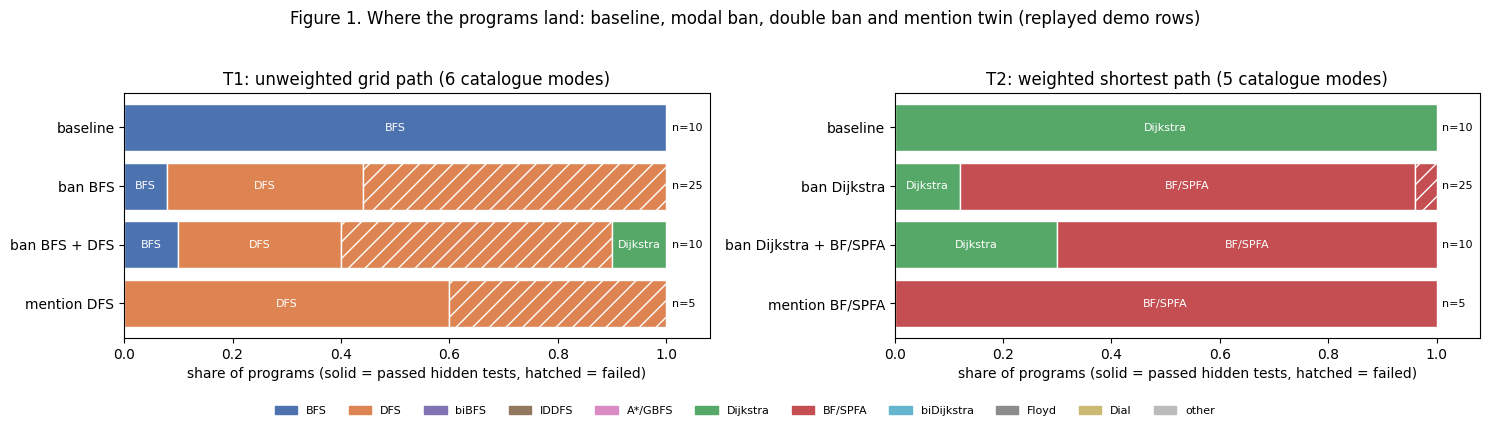

In [29]:
MODE_COLORS = {"bfs": "#4C72B0", "dfs": "#DD8452", "bibfs": "#8172B3", "iddfs": "#937860", "astar_gbfs": "#DA8BC3",
               "dijkstra": "#55A868", "bf_spfa": "#C44E52", "bidijkstra": "#64B5CD", "floyd": "#8C8C8C",
               "dial": "#CCB974", OTHER: "#BBBBBB"}
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "biBFS", "iddfs": "IDDFS", "astar_gbfs": "A*/GBFS", "dijkstra": "Dijkstra",
         "bf_spfa": "BF/SPFA", "bidijkstra": "biDijkstra", "floyd": "Floyd", "dial": "Dial", OTHER: "other"}
COND_ORDER = {"t1": ["baseline", "ban:bfs", "succession:2", "mention:dfs"],
              "t2": ["baseline", "ban:dijkstra", "succession:2", "mention:bf_spfa"]}
COND_NAME = {"baseline": "baseline", "ban:bfs": "ban BFS", "ban:dijkstra": "ban Dijkstra",
             "mention:dfs": "mention DFS", "mention:bf_spfa": "mention BF/SPFA"}
by_cond = SCORE["by_cond"]

# ---- Figure 1: label distribution per condition (all programs with code; hatched = failed the hidden tests) ----
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, task in zip(axes, TASKS):
    conds_t = [c for c in COND_ORDER[task] if by_cond.get(f"{task}|{c}")]
    names_t = []
    for i, c in enumerate(conds_t):
        rows = [r for r in by_cond[f"{task}|{c}"] if r["label"] != NO_CODE]
        left = 0.0
        for m in MODES[task] + [OTHER]:
            for passed in (True, False):
                k = sum(1 for r in rows if r["label"] == m and bool(r["passed"]) == passed)
                if k:
                    w = k / max(1, len(rows))
                    ax.barh(i, w, left=left, color=MODE_COLORS[m], edgecolor="white", hatch=None if passed else "//")
                    if w >= 0.08 and passed:
                        ax.text(left + w / 2, i, SHORT[m], ha="center", va="center", fontsize=8, color="white")
                    left += w
        if c == "succession:2":
            banned = json.loads(FROZEN[f"predictions/{task}_succ_step2.json"])["banned_in_order"]
            names_t.append("ban " + " + ".join(SHORT[b] for b in banned))
        else:
            names_t.append(COND_NAME[c])
        ax.text(1.01, i, f"n={len(rows)}", va="center", fontsize=8)
    ax.set_yticks(range(len(conds_t)))
    ax.set_yticklabels(names_t)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("share of programs (solid = passed hidden tests, hatched = failed)")
    ax.set_title({"t1": "T1: unweighted grid path (6 catalogue modes)", "t2": "T2: weighted shortest path (5 catalogue modes)"}[task])
handles = [plt.Rectangle((0, 0), 1, 1, color=MODE_COLORS[m]) for m in MODE_COLORS]
fig.legend(handles, [SHORT[m] for m in MODE_COLORS], loc="lower center", ncol=11, fontsize=8, frameon=False)
fig.suptitle("Figure 1. Where the programs land: baseline, modal ban, double ban and mention twin (replayed demo rows)")
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
plt.show()

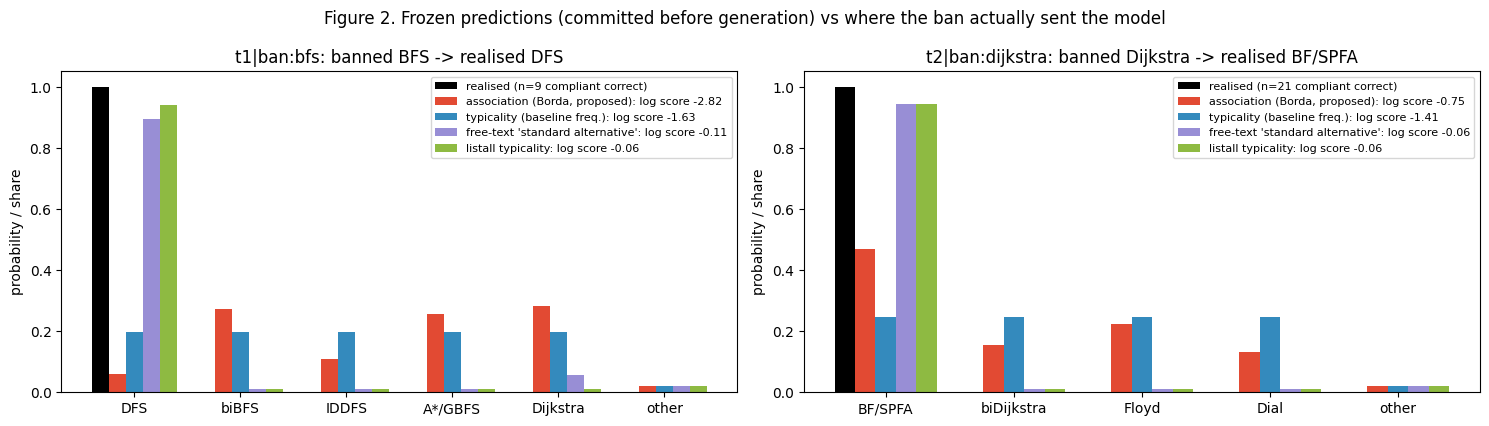

In [30]:
# ---- Figure 2: frozen predictions vs realised compliant correct labels for the scored events ----
PRED_SHOW = [("assoc", "association (Borda, proposed)"), ("freq", "typicality (baseline freq.)"),
             ("freetext", "free-text 'standard alternative'"), ("freq_listall", "listall typicality")]
scored = SCORE["scored"]
if scored:
    fig, axes = plt.subplots(1, len(scored), figsize=(7.5 * len(scored), 4.3), squeeze=False)
    for ax, s in zip(axes[0], scored):
        S = s["out"]["survivors"] + [OTHER]
        x = np.arange(len(S))
        width = 0.16
        ax.bar(x - 2 * width, [s["out"]["realised_shares"][y] for y in S], width, color="black",
               label=f"realised (n={s['out']['n_compliant']} compliant correct)")
        for j, (name, lab) in enumerate(PRED_SHOW):
            q = s["pred"]["composed"][name]
            ls = s["score"]["per_predictor"][name]["log_score"]
            ax.bar(x + (j - 1) * width, [q[y] for y in S], width, label=f"{lab}: log score {ls:.2f}",
                   color=["#E24A33", "#348ABD", "#988ED5", "#8EBA42"][j])
        ax.set_xticks(x)
        ax.set_xticklabels([SHORT[y] for y in S])
        ax.set_ylim(0, 1.05)
        ax.set_ylabel("probability / share")
        ax.set_title(f"{s['event_id']}: banned {', '.join(SHORT[b] for b in s['banned'])} -> realised "
                     f"{SHORT.get(s['out']['realised_mode'], s['out']['realised_mode'])}")
        ax.legend(fontsize=8, loc="upper right")
    fig.suptitle("Figure 2. Frozen predictions (committed before generation) vs where the ban actually sent the model")
    fig.tight_layout()
    plt.show()

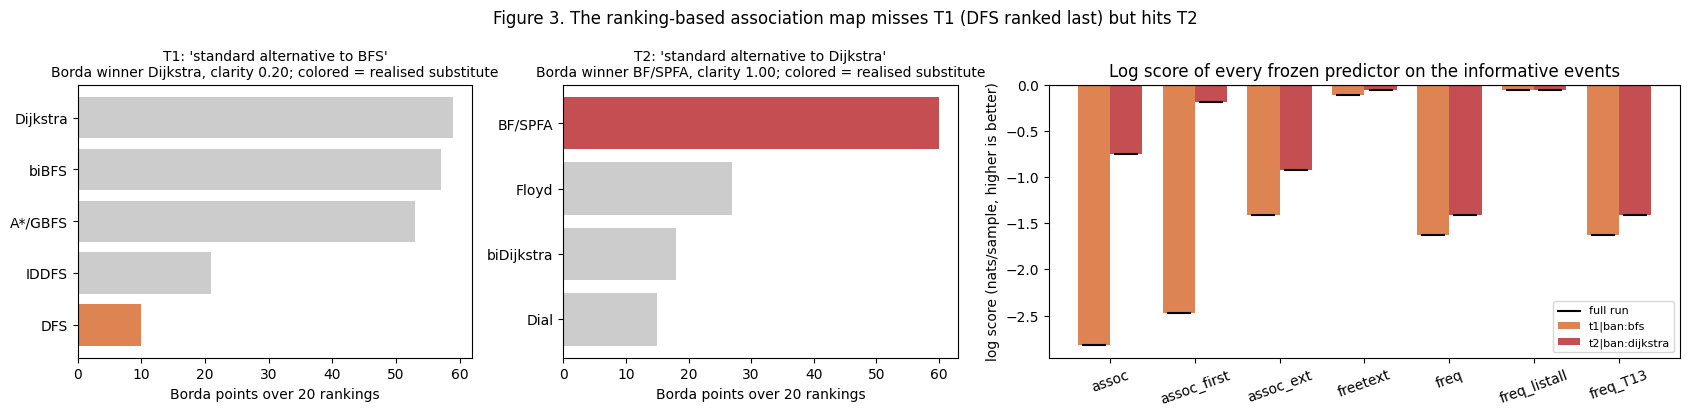

In [31]:
# ---- Figure 3: the model's own association maps and the log scores of every predictor ----
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.6]})
for ax, (task, x) in zip(axes[:2], (("t1", "bfs"), ("t2", "dijkstra"))):
    q = assoc["qwen"][task][x]
    realised = full_ev[f"{task}|ban:{x}"]["realised_mode"]
    order = sorted(q["borda_points"], key=lambda y: q["borda_points"][y])
    ax.barh([SHORT[y] for y in order], [q["borda_points"][y] for y in order],
            color=[MODE_COLORS[y] if y == realised else "#CCCCCC" for y in order])
    ax.set_title(f"{task.upper()}: 'standard alternative to {SHORT[x]}'\nBorda winner {SHORT[q['borda_winner']]}, "
                 f"clarity {q['clarity']:.2f}; colored = realised substitute", fontsize=10)
    ax.set_xlabel(f"Borda points over {q['n_rankings']} rankings")
ax = axes[2]
if scored:
    names = [n for n in ("assoc", "assoc_first", "assoc_ext", "freetext", "freq", "freq_listall", "freq_T13")
             if all(n in s["score"]["per_predictor"] for s in scored)]
    xx = np.arange(len(names))
    for j, s in enumerate(scored):
        vals = [s["score"]["per_predictor"][n]["log_score"] for n in names]
        ax.bar(xx + (j - 0.5) * 0.38, vals, 0.38, label=s["event_id"], color=["#DD8452", "#C44E52"][j % 2])
        fv = [full_contest[s["event_id"]]["per_predictor"][n]["log_score"] for n in names]
        ax.scatter(xx + (j - 0.5) * 0.38, fv, marker="_", s=300, color="black", zorder=3,
                   label="full run" if j == 0 else None)
    ax.set_xticks(xx)
    ax.set_xticklabels(names, rotation=20)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel("log score (nats/sample, higher is better)")
    ax.set_title("Log score of every frozen predictor on the informative events")
    ax.legend(fontsize=8)
fig.suptitle("Figure 3. The ranking-based association map misses T1 (DFS ranked last) but hits T2")
fig.tight_layout()
plt.show()

In [32]:
# ---- Summary: demo subset vs full run ----
def _ev(eid, key):
    return next((e[key] for e in SCORE["event_table"] if e["event_id"] == eid), None)


def _pp(eid, name, key="log_score"):
    s = next((s for s in SCORE["contest"]["events"] if s["event_id"] == eid), None)
    return s["per_predictor"][name][key] if s else None


fc = full_contest
summary_rows = [
    ("T1 baseline: share BFS", base["t1"]["baseline"]["freq"]["f"]["bfs"], 1.0),
    ("T2 baseline: share Dijkstra", base["t2"]["baseline"]["freq"]["f"]["dijkstra"], 1.0),
    ("T1 ban BFS: compliance", _ev("t1|ban:bfs", "compliance"), full_ev["t1|ban:bfs"]["compliance"]),
    ("T2 ban Dijkstra: compliance", _ev("t2|ban:dijkstra", "compliance"), full_ev["t2|ban:dijkstra"]["compliance"]),
    ("T1 ban BFS: realised substitute", _ev("t1|ban:bfs", "realised_mode"), full_ev["t1|ban:bfs"]["realised_mode"]),
    ("T2 ban Dijkstra: realised substitute", _ev("t2|ban:dijkstra", "realised_mode"), full_ev["t2|ban:dijkstra"]["realised_mode"]),
    ("T1 association nomination", _pp("t1|ban:bfs", "assoc", "nomination"), fc["t1|ban:bfs"]["per_predictor"]["assoc"]["nomination"]),
    ("T2 association nomination", _pp("t2|ban:dijkstra", "assoc", "nomination"), fc["t2|ban:dijkstra"]["per_predictor"]["assoc"]["nomination"]),
    ("T1 log score assoc / freq", f"{_pp('t1|ban:bfs', 'assoc')} / {_pp('t1|ban:bfs', 'freq')}",
     f"{fc['t1|ban:bfs']['per_predictor']['assoc']['log_score']} / {fc['t1|ban:bfs']['per_predictor']['freq']['log_score']}"),
    ("T2 log score assoc / freq", f"{_pp('t2|ban:dijkstra', 'assoc')} / {_pp('t2|ban:dijkstra', 'freq')}",
     f"{fc['t2|ban:dijkstra']['per_predictor']['assoc']['log_score']} / {fc['t2|ban:dijkstra']['per_predictor']['freq']['log_score']}"),
    ("mean paired assoc - freq (nats/sample)", pa["mean_paired_diff"] if pa else None, fpa["mean_paired_diff"]),
    ("association wins", f"{pa['assoc_wins']} of {pa['assoc_wins_of']}" if pa else None,
     f"{fpa['assoc_wins']} of {fpa['assoc_wins_of']}"),
    ("T1 double ban: compliance", _ev("t1|succession:2", "compliance"), full_ev["t1|succession:2"]["compliance"]),
    ("T2 double ban: compliance", _ev("t2|succession:2", "compliance"), full_ev["t2|succession:2"]["compliance"]),
]


def _fmt(v):
    if isinstance(v, float):
        return f"{v:.3f}"
    if isinstance(v, str) and " / " in v:
        return " / ".join(_fmt(float(p)) if p not in ("None", "nan") else p for p in v.split(" / "))
    return str(v)


print(pd.DataFrame([(k, _fmt(a), _fmt(b)) for k, a, b in summary_rows],
                   columns=["quantity", f"demo ({len(LABELLED)} replayed programs)", "full run (3,260 programs)"]).to_string(index=False))

                              quantity demo (100 replayed programs) full run (3,260 programs)
                T1 baseline: share BFS                        1.000                     1.000
           T2 baseline: share Dijkstra                        1.000                     1.000
                T1 ban BFS: compliance                        0.920                     0.900
           T2 ban Dijkstra: compliance                        0.880                     0.910
       T1 ban BFS: realised substitute                          dfs                       dfs
  T2 ban Dijkstra: realised substitute                      bf_spfa                   bf_spfa
             T1 association nomination                     dijkstra                  dijkstra
             T2 association nomination                      bf_spfa                   bf_spfa
             T1 log score assoc / freq              -2.817 / -1.630           -2.817 / -1.630
             T2 log score assoc / freq              -0.755 /

## Takeaways

- **Bans substitute; they do not just subtract.** Both baselines are fully collapsed, so the typicality ladder is
  uniform over the survivors and cannot nominate anything. Yet each modal ban sent essentially all compliant
  programs to **one** substitute: DFS on T1 and Bellman-Ford/SPFA on T2.
- **The model's ranked association map is not the same instrument as its free-text answer.** Asked to *rank*
  alternatives to BFS, Qwen3-8B put Dijkstra first and DFS last (clarity 0.20), and the Borda predictor missed T1.
  Asked in *free text*, it answered "DFS", which is where the ban actually went. On T2 both instruments agree.
- **Multi-name bans need mechanism-level compliance checks.** With two banned names, the model re-implemented the
  banned mechanism under another description ("backtracking", "BFS with pruning"), often without naming it.
- **Mentioning is recommending.** Mention twins move up to +100 pp of mass to the mentioned mode, so they are not a
  neutral control.

All numbers here are descriptive: two tasks and two informative events cannot support an inferential claim. To
scale the demo, raise `MAX_ROWS_PER_CONDITION` (up to 25 in the demo data). To reproduce every number exactly from
all 3,260 programs, run the artifact's Path A (`reproducibility.md`). Full regeneration (Path B) needs a GPU with at
least 20 GB, vLLM 0.11 and an OpenRouter key.